# PJM Hourly Energy Consumption Forecast 

## Business objective
Analyze PJM hourly electricity consumption in MW, understand its time-based patterns, prepare a reliable base dataset for modeling, and support the later requirements of:
- using the **last year as the test set**,
- studying hourly, seasonal and long-term patterns,
- considering holiday effects where appropriate, and
- producing a **30-day forecast**.

# Week 1 - EDA
 
**Week 1 milestone:** Exploratory Data Analysis (EDA)

## 1. Import libraries and load the dataset


In [1]:
# Purpose: import the libraries required for data loading, numerical operations, and plotting.
# Read the original Excel dataset and convert Datetime to pandas datetime so time-based analysis is reliable.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_excel("PJMW_MW_Hourly.xlsx")
df["Datetime"] = pd.to_datetime(df["Datetime"])

### Raw data preview


In [2]:
# Quick preview of the raw dataset to verify that the expected columns and values were loaded correctly.

df.head()

,Datetime,PJMW_MW
0,2002-12-31 01:00:00,5077
1,2002-12-31 02:00:00,4939
2,2002-12-31 03:00:00,4885
3,2002-12-31 04:00:00,4857
4,2002-12-31 05:00:00,4930


## 2. Basic dataset inspection


### Dataset shape and data types


In [3]:
# Check the dataset size and data types before cleaning.
# This confirms how many observations are available and whether Datetime/consumption are stored in usable types.

print("Shape:", df.shape)
print("\nData types:")
print(df.dtypes)

Shape: (143206, 2)

Data types:
Datetime    datetime64[ns]
PJMW_MW              int64
dtype: object


### Missing values and duplicates


In [4]:
# Check missing values and exact duplicate rows first.
# Then check duplicate timestamps separately 
# because duplicate timestamps can affect time-series calculations even when full rows are different.

print("Missing values:")
print(df.isna().sum())

print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate Datetime values:", df["Datetime"].duplicated().sum())

Missing values:
Datetime    0
PJMW_MW     0
dtype: int64

Duplicate rows: 0
Duplicate Datetime values: 4


### Date range and descriptive statistics


In [5]:
# Establish the time span covered by the dataset and inspect the distribution of electricity consumption.
# Descriptive statistics help identify the typical level, spread, minimum, and maximum before deeper EDA.

print("Date range:")
print(df["Datetime"].min(), "to", df["Datetime"].max())

print("\nDescriptive statistics for PJMW_MW:")
print(df["PJMW_MW"].describe())

Date range:
2002-04-01 01:00:00 to 2018-08-03 00:00:00

Descriptive statistics for PJMW_MW:
count    143206.000000
mean       5602.375089
std         979.142872
min         487.000000
25%        4907.000000
50%        5530.000000
75%        6252.000000
max        9594.000000
Name: PJMW_MW, dtype: float64


### Initial finding

The raw dataset contains **143,206 rows and 2 columns**. There are no null values and no fully duplicated rows, but duplicate timestamps require investigation before time-series analysis.


## 3. Chronological integrity and timestamp anomalies


### Sort chronologically and inspect time intervals


In [6]:
# Sort by time before calculating differences between consecutive observations.
# Time gaps are then used to identify duplicate timestamps, normal hourly intervals, clock-change transitions, 
# and other irregularities.

df = df.sort_values("Datetime").reset_index(drop=True)
time_diff = df["Datetime"].diff()

print("1-hour intervals:", (time_diff == pd.Timedelta(hours=1)).sum())
print("2-hour gaps:", (time_diff == pd.Timedelta(hours=2)).sum())
print("Duplicate timestamp transitions:", (time_diff == pd.Timedelta(0)).sum())
print("Other interval changes:", (~time_diff.isin([pd.Timedelta(hours=1), pd.Timedelta(hours=2), pd.Timedelta(0)])).sum())

1-hour intervals: 143171
2-hour gaps: 30
Duplicate timestamp transitions: 4
Other interval changes: 1


### Duplicate timestamp records


In [7]:
# Display every record involved in a duplicated timestamp so we can inspect the actual consumption values.
# This is important before deciding how duplicate timestamps should be handled.

duplicate_records = df[df["Datetime"].duplicated(keep= False)] # To get all the occurrence of duplicate values
print(duplicate_records.to_string(index=False)) # For clean display of the values

           Datetime  PJMW_MW
2014-11-02 02:00:00     4571
2014-11-02 02:00:00     4613
2015-11-01 02:00:00     3927
2015-11-01 02:00:00     3832
2016-11-06 02:00:00     4114
2016-11-06 02:00:00     4089
2017-11-05 02:00:00     3984
2017-11-05 02:00:00     4042


### Inspect the 2-hour gaps


In [8]:
# Investigate every 2-hour transition to determine whether it follows a recurring clock-change pattern 
# or represents a genuine missing hour.

# Selecting timestamps where the gap = 2-hours
gap_report = df.loc[time_diff == pd.Timedelta(hours=2), ["Datetime"]].copy()

# Adding previous timestamps to know where exactly the 2-hour gap occurred
gap_report["Previous_Datetime"] = df.loc[gap_report.index - 1, "Datetime"].values

# Extracting day of the week from each timestamp
gap_report["Day"] = gap_report["Datetime"].dt.day_name()

print("Number of two-hour gaps:" , len(gap_report))
print(gap_report.to_string(index=False))

Number of two-hour gaps: 30
           Datetime   Previous_Datetime    Day
2002-04-07 04:00:00 2002-04-07 02:00:00 Sunday
2002-10-27 03:00:00 2002-10-27 01:00:00 Sunday
2003-04-06 04:00:00 2003-04-06 02:00:00 Sunday
2003-10-26 03:00:00 2003-10-26 01:00:00 Sunday
2004-04-04 04:00:00 2004-04-04 02:00:00 Sunday
2004-10-31 03:00:00 2004-10-31 01:00:00 Sunday
2005-04-03 04:00:00 2005-04-03 02:00:00 Sunday
2005-10-30 03:00:00 2005-10-30 01:00:00 Sunday
2006-04-02 04:00:00 2006-04-02 02:00:00 Sunday
2006-10-29 03:00:00 2006-10-29 01:00:00 Sunday
2007-03-11 04:00:00 2007-03-11 02:00:00 Sunday
2007-11-04 03:00:00 2007-11-04 01:00:00 Sunday
2008-03-09 04:00:00 2008-03-09 02:00:00 Sunday
2008-11-02 03:00:00 2008-11-02 01:00:00 Sunday
2009-03-08 04:00:00 2009-03-08 02:00:00 Sunday
2009-11-01 03:00:00 2009-11-01 01:00:00 Sunday
2010-03-14 04:00:00 2010-03-14 02:00:00 Sunday
2010-11-07 03:00:00 2010-11-07 01:00:00 Sunday
2010-12-10 01:00:00 2010-12-09 23:00:00 Friday
2011-03-13 04:00:00 2011-03-13 0

### Timestamp-quality interpretation

The repeated 2 AM timestamps occur around daylight-saving clock changes. Because the source does not contain a timezone/DST indicator, the duplicate readings cannot be distinguished as separate absolute timestamps. For a single timestamp series, they are consolidated by taking their mean.

The remaining isolated 2-hour gap is **2010-12-10 00:00:00**, which is treated as the genuine missing observation.


### Missing Hourly Timestamps

In [9]:
# Create the ideal continuous hourly timeline from the first to the last observed timestamp.
# Comparing it with the actual timestamps identifies every absent hourly label; 
# these gaps must then be interpreted before filling anything.

full_range = pd.date_range(
    start=df["Datetime"].min(),
    end=df["Datetime"].max(),
    freq="h"
)

missing_hours = full_range.difference(df["Datetime"])

print("Number of missing hourly timestamps:", len(missing_hours))
print("\nMissing Hourly Timestamps" , missing_hours)

Number of missing hourly timestamps: 30

Missing Hourly Timestamps DatetimeIndex(['2002-04-07 03:00:00', '2002-10-27 02:00:00',
               '2003-04-06 03:00:00', '2003-10-26 02:00:00',
               '2004-04-04 03:00:00', '2004-10-31 02:00:00',
               '2005-04-03 03:00:00', '2005-10-30 02:00:00',
               '2006-04-02 03:00:00', '2006-10-29 02:00:00',
               '2007-03-11 03:00:00', '2007-11-04 02:00:00',
               '2008-03-09 03:00:00', '2008-11-02 02:00:00',
               '2009-03-08 03:00:00', '2009-11-01 02:00:00',
               '2010-03-14 03:00:00', '2010-11-07 02:00:00',
               '2010-12-10 00:00:00', '2011-03-13 03:00:00',
               '2011-11-06 02:00:00', '2012-03-11 03:00:00',
               '2012-11-04 02:00:00', '2013-03-10 03:00:00',
               '2013-11-03 02:00:00', '2014-03-09 03:00:00',
               '2015-03-08 03:00:00', '2016-03-13 03:00:00',
               '2017-03-12 03:00:00', '2018-03-11 03:00:00'],
              dty

### Timestamp-gap interpretation

The continuous hourly check identified **30 absent timestamp labels**.

These do **not** mean that 30 genuine consumption observations are missing. Most follow the recurring clock-change pattern in the source timestamps. After investigating the 2-hour transitions, **2010-12-10 00:00:00** was identified as the one isolated genuine missing observation.

**NOTE:** `full_range.difference()` is used to detect absent hourly labels; the gap investigation is then used to distinguish structural clock-change gaps from a genuine missing observation.

## 4. Consolidate timestamps and handle the genuine missing observation


### Consolidate duplicate timestamps


In [10]:
# Consolidate repeated timestamps into one timestamp by taking the mean of their consumption values.
# The source has no timezone/DST indicator, so the mean provides one representative value for the single timestamp series.

# Taking average of each duplicated timestamp group and sorting the values
clean = (df.groupby("Datetime", as_index=False)["PJMW_MW"].mean().sort_values("Datetime").reset_index(drop=True))

print("\nRows after timestamp consolidation:", len(clean))
print("Duplicate timestamps after consolidation:", clean["Datetime"].duplicated().sum())

print("\nRows before timestamp consolidation:", len(df))
print("Previous Duplicate timestamps:", df['Datetime'].duplicated().sum())

# We had 4 duplicated timestamp and after consolidating them, the total rows count got reduced by 4


Rows after timestamp consolidation: 143202
Duplicate timestamps after consolidation: 0

Rows before timestamp consolidation: 143206
Previous Duplicate timestamps: 4


### Fill the isolated missing timestamp


In [11]:
# Build a detailed report for every 2-hour transition.
# This report lets us reconstruct the timestamp that would normally occur between the two observed timestamps.

# Select timestamps where the gap from the previous observation is exactly 2 hours
gap_check = df.loc[time_diff == pd.Timedelta(hours=2),["Datetime"]].copy() 

#copy() - Creates an independent copy so we can safely add new columns such as Previous_Datetime, Time_Gap, and Missing_Datetime 
# without modifying the original df.

# Add the timestamp of the previous observation for each 2-hour gap
gap_check["Previous_Datetime"] = df.loc[gap_check.index - 1, "Datetime"].values

# Calculate and display the actual time difference between the two timestamps
gap_check["Time_Gap"] = (gap_check["Datetime"] - gap_check["Previous_Datetime"])

# Calculate the timestamp that should occur between the two observations
# by adding one hour to the previous timestamp
gap_check["Missing_Datetime"] = (gap_check["Previous_Datetime"] + pd.Timedelta(hours=1))

# Display the complete gap report without the DataFrame index
print(gap_check.to_string(index=False))

           Datetime   Previous_Datetime        Time_Gap    Missing_Datetime
2002-04-07 04:00:00 2002-04-07 02:00:00 0 days 02:00:00 2002-04-07 03:00:00
2002-10-27 03:00:00 2002-10-27 01:00:00 0 days 02:00:00 2002-10-27 02:00:00
2003-04-06 04:00:00 2003-04-06 02:00:00 0 days 02:00:00 2003-04-06 03:00:00
2003-10-26 03:00:00 2003-10-26 01:00:00 0 days 02:00:00 2003-10-26 02:00:00
2004-04-04 04:00:00 2004-04-04 02:00:00 0 days 02:00:00 2004-04-04 03:00:00
2004-10-31 03:00:00 2004-10-31 01:00:00 0 days 02:00:00 2004-10-31 02:00:00
2005-04-03 04:00:00 2005-04-03 02:00:00 0 days 02:00:00 2005-04-03 03:00:00
2005-10-30 03:00:00 2005-10-30 01:00:00 0 days 02:00:00 2005-10-30 02:00:00
2006-04-02 04:00:00 2006-04-02 02:00:00 0 days 02:00:00 2006-04-02 03:00:00
2006-10-29 03:00:00 2006-10-29 01:00:00 0 days 02:00:00 2006-10-29 02:00:00
2007-03-11 04:00:00 2007-03-11 02:00:00 0 days 02:00:00 2007-03-11 03:00:00
2007-11-04 03:00:00 2007-11-04 01:00:00 0 days 02:00:00 2007-11-04 02:00:00
2008-03-09 0

In [12]:
# The gap investigation identified 2010-12-10 00:00:00 as the one genuine isolated missing observation.
# It is not present in the raw dataset; 
# the timestamp is reconstructed from the hourly sequence before filling its consumption value.

# Creating a Pandas Timestamp object for the exact missing datetime identified
missing_time = pd.Timestamp("2010-12-10 00:00:00")

# Find the last available consumption value before the missing timestamp
before = clean.loc[clean["Datetime"] < missing_time, "PJMW_MW"].iloc[-1]

# Find the first available consumption value after the missing timestamp.
after = clean.loc[clean["Datetime"] > missing_time, "PJMW_MW"].iloc[0]

# Calculate the average of the immediately adjacent values
missing_value = (before + after) / 2

print("Previous hour value:", before, "MW")
print("Next hour value:", after, "MW")
print("Filled value:", round(missing_value, 2), "MW")

Previous hour value: 6972.0 MW
Next hour value: 6280.0 MW
Filled value: 6626.0 MW


In [13]:
# Insert the reconstructed missing observation into the cleaned timestamp series and restore chronological order.
# ignore_index=True creates a fresh continuous row index after adding the new observation.

# Combine the original cleaned data with this new row
clean = pd.concat([clean, pd.DataFrame({"Datetime": [missing_time], "PJMW_MW": [missing_value]})], 
                  ignore_index=True).sort_values("Datetime").reset_index(drop=True)
clean

# ignore_index=True tells Pandas to create a new continuous index instead of preserving the old indexes

,Datetime,PJMW_MW
0,2002-04-01 01:00:00,4374.0
1,2002-04-01 02:00:00,4306.0
2,2002-04-01 03:00:00,4322.0
3,2002-04-01 04:00:00,4359.0
4,2002-04-01 05:00:00,4436.0
...,...,...
143198,2018-08-02 20:00:00,6545.0
143199,2018-08-02 21:00:00,6496.0
143200,2018-08-02 22:00:00,6325.0
143201,2018-08-02 23:00:00,5892.0


### Validate timestamp consolidation and missing-value repair


In [14]:
# Validate the repair: the cleaned data should have no missing target values and no duplicate timestamps.

print("Rows after repair:", len(clean))
print("Missing values:")
print(clean.isna().sum())
print("Duplicate timestamps:", clean["Datetime"].duplicated().sum())

Rows after repair: 143203
Missing values:
Datetime    0
PJMW_MW     0
dtype: int64
Duplicate timestamps: 0


### Data-quality note

The repeated timestamps were consolidated, while the one genuine missing target value was filled using the mean of its immediately adjacent hourly observations. No additional values were artificially inserted for the recurring clock-change pattern.


## 5. Distribution and outlier screening


### IQR-based outlier screening


In [15]:
# Use the IQR rule to screen for unusually low/high consumption values.
# These are potential outliers only; electricity demand can naturally vary by hour, weekday, and season.

Q1 = clean["PJMW_MW"].quantile(0.25)
Q3 = clean["PJMW_MW"].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
potential_outliers = clean[(clean["PJMW_MW"] < lower_bound) | (clean["PJMW_MW"] > upper_bound)]
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Potential IQR outliers:", len(potential_outliers))

Q1: 4907.0
Q3: 6252.0
IQR: 1345.0
Lower bound: 2889.5
Upper bound: 8269.5
Potential IQR outliers: 703


### Lowest and highest observations


In [16]:
# Inspect the most extreme consumption observations with their timestamps.
# This helps determine whether IQR-flagged values look like plausible demand or isolated data-quality issues.

print("Lowest observations:")
print(clean.nsmallest(10, "PJMW_MW")[["Datetime", "PJMW_MW"]])
print("\nHighest observations:")
print(clean.nlargest(10, "PJMW_MW")[["Datetime", "PJMW_MW"]])

Lowest observations:
                 Datetime  PJMW_MW
10148 2003-05-29 00:00:00    487.0
87674 2012-04-02 00:00:00   2553.0
87666 2012-04-01 16:00:00   2574.0
87667 2012-04-01 17:00:00   2586.0
87668 2012-04-01 18:00:00   2600.0
87669 2012-04-01 19:00:00   2630.0
87665 2012-04-01 15:00:00   2663.0
87673 2012-04-01 23:00:00   2690.0
87664 2012-04-01 14:00:00   2721.0
87663 2012-04-01 13:00:00   2878.0

Highest observations:
                  Datetime  PJMW_MW
112974 2015-02-20 08:00:00   9594.0
112962 2015-02-19 20:00:00   9536.0
112973 2015-02-20 07:00:00   9512.0
112961 2015-02-19 19:00:00   9489.0
112975 2015-02-20 09:00:00   9481.0
112963 2015-02-19 21:00:00   9424.0
113070 2015-02-24 08:00:00   9366.0
103171 2014-01-07 20:00:00   9349.0
138183 2018-01-05 20:00:00   9342.0
138182 2018-01-05 19:00:00   9325.0


### Distribution of hourly consumption


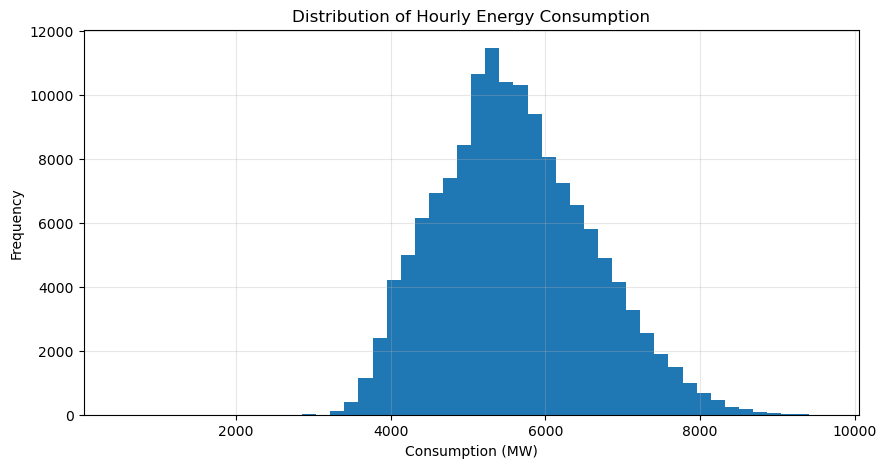

In [17]:
# Visualize the overall distribution of hourly consumption.
# The histogram helps us understand the concentration and spread of demand 
# before deciding whether any extreme values need investigation.

plt.figure(figsize=(10, 5))
plt.hist(clean["PJMW_MW"], bins=50)
plt.title("Distribution of Hourly Energy Consumption")
plt.xlabel("Consumption (MW)")
plt.ylabel("Frequency")
plt.grid(True, alpha=0.3)
plt.show()

### Outlier interpretation

The IQR method is used as a **screening technique**, not as an automatic deletion rule. Electricity demand naturally varies with hour, weekday and season, so high or low values can be legitimate demand observations.

The isolated **487 MW** reading at **2003-05-29 00:00** is investigated separately because it is far below the surrounding demand pattern.


## 6. Investigate and correct the isolated local anomaly


### Identify the local reference value


In [18]:
# Investigate the isolated 487 MW observation using comparable observations at the same hour within a local ±7-day window.
# A local same-hour median is used as a robust reference because electricity demand has strong hourly and weekly patterns.

anomaly_time = pd.Timestamp("2003-05-29 00:00:00")
same_hour_window = clean[(clean["Datetime"].dt.hour == anomaly_time.hour) & 
    (clean["Datetime"] >= anomaly_time - pd.Timedelta(days=7)) & 
    (clean["Datetime"] <= anomaly_time + pd.Timedelta(days=7)) & 
    (clean["Datetime"] != anomaly_time)]

original_value = clean.loc[clean["Datetime"] == anomaly_time, "PJMW_MW"].iloc[0]
replacement_value = int(round(same_hour_window["PJMW_MW"].median()))

print("Original value:", original_value, "MW")
print("Same-hour ±7-day median:", replacement_value, "MW")

Original value: 487.0 MW
Same-hour ±7-day median: 4786 MW


### Replace the isolated anomaly


In [19]:
# Replace only the specifically investigated local anomaly with the robust same-hour reference value.
# No other IQR-flagged observations are automatically removed or modified.

clean.loc[clean["Datetime"] == anomaly_time, "PJMW_MW"] = replacement_value
print("Corrected value:", clean.loc[clean["Datetime"] == anomaly_time, "PJMW_MW"].iloc[0], "MW")

Corrected value: 4786.0 MW


### Check the surrounding observations


In [20]:
# Inspect the observations immediately around the corrected timestamp.
# This provides a simple before/after context check to confirm that the replacement is locally reasonable.

nearby = clean[(clean["Datetime"] >= anomaly_time - pd.Timedelta(hours=2)) & 
    (clean["Datetime"] <= anomaly_time + pd.Timedelta(hours=2))]
print(nearby)

                 Datetime  PJMW_MW
10146 2003-05-28 22:00:00   5746.0
10147 2003-05-28 23:00:00   5317.0
10148 2003-05-29 00:00:00   4786.0
10149 2003-05-29 01:00:00   4560.0
10150 2003-05-29 02:00:00   4424.0


### Method note

The replacement uses the median of the **same hour of day within a ±7-day local window**. This preserves the hourly pattern while reducing the influence of unusually high or low neighboring observations.


## 7. Final cleaned-base validation


### Validate the cleaned dataset


In [21]:
# Final validation of the cleaned base dataset before creating EDA features.
# Confirm row count, missing values, and timestamp uniqueness after all data-quality repairs.

print("Cleaned-base shape:", clean.shape)
print("\nMissing values:")
print(clean.isna().sum())
print("\nDuplicate timestamps:", clean["Datetime"].duplicated().sum())

Cleaned-base shape: (143203, 2)

Missing values:
Datetime    0
PJMW_MW     0
dtype: int64

Duplicate timestamps: 0


Datetime    0
PJMW_MW     0
dtype: int64

Duplicate timestamps: 0


### Check date range and remaining time transitions


In [22]:
# Recheck the time range and count the remaining 2-hour transitions.
# Recurring clock-change transitions are expected to remain because they are a property of the source timestamp representation.

clean_diff = clean["Datetime"].diff()
print("Date range:", clean["Datetime"].min(), "to", clean["Datetime"].max())
print("Remaining 2-hour transitions:", (clean_diff == pd.Timedelta(hours=2)).sum())

Date range: 2002-04-01 01:00:00 to 2018-08-03 00:00:00
Remaining 2-hour transitions: 29


### Cleaned base dataset preview


In [23]:
# Preview the cleaned base dataset after validation.

clean.head()

,Datetime,PJMW_MW
0,2002-04-01 01:00:00,4374.0
1,2002-04-01 02:00:00,4306.0
2,2002-04-01 03:00:00,4322.0
3,2002-04-01 04:00:00,4359.0
4,2002-04-01 05:00:00,4436.0


### Validation result

The cleaned base dataset contains **143,203 rows**, has no missing target values, and has unique timestamps. The recurring clock-change transitions are retained as a property of the source time representation rather than being incorrectly treated as missing observations.


## 8. Create basic time features for EDA


### Extract calendar/time features


In [24]:
# Create a separate EDA copy so the cleaned base dataset remains unchanged.
# Extract calendar/time attributes needed to analyze hourly, weekly, seasonal, and long-term patterns.

eda = clean.copy()
eda["Year"] = eda["Datetime"].dt.year
eda["Month"] = eda["Datetime"].dt.month
eda["Day"] = eda["Datetime"].dt.day
eda["Hour"] = eda["Datetime"].dt.hour
eda["DayOfWeek"] = eda["Datetime"].dt.dayofweek
eda["Is_Weekend"] = (eda["DayOfWeek"] >= 5).astype(int)

### Time-feature preview


In [25]:
# Preview the engineered EDA features and verify that the new calendar columns were created correctly.

eda.head()

,Datetime,PJMW_MW,Year,Month,Day,Hour,DayOfWeek,Is_Weekend
0,2002-04-01 01:00:00,4374.0,2002,4,1,1,0,0
1,2002-04-01 02:00:00,4306.0,2002,4,1,2,0,0
2,2002-04-01 03:00:00,4322.0,2002,4,1,3,0,0
3,2002-04-01 04:00:00,4359.0,2002,4,1,4,0,0
4,2002-04-01 05:00:00,4436.0,2002,4,1,5,0,0


These are **basic calendar features for EDA**. Lag, rolling and other model-specific features will be created later during Model Building after the time-based split.


## 9. Overall time-series trend


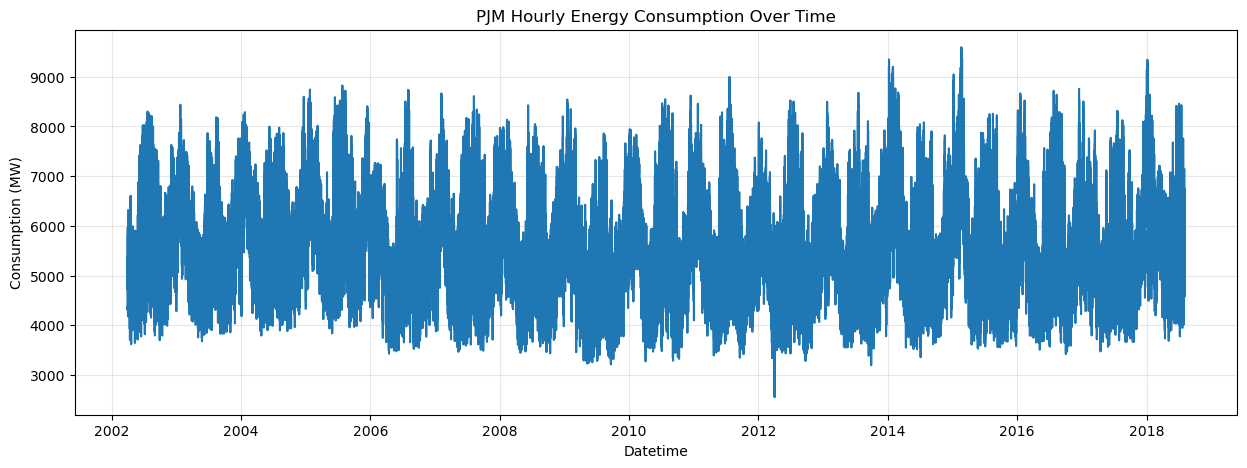

In [26]:
# Plot the complete cleaned time series to understand long-term variation and changes in consumption over time.

plt.figure(figsize=(15, 5))
plt.plot(eda["Datetime"], eda["PJMW_MW"])
plt.title("PJM Hourly Energy Consumption Over Time")
plt.xlabel("Datetime")
plt.ylabel("Consumption (MW)")
plt.grid(True, alpha=0.3)
plt.show()

### Key observation

The series shows substantial variation over time, supporting the need for time-based features and a chronological validation strategy rather than a random train/test split.


## 10. Average consumption by hour of day


### Calculate hourly averages


In [27]:
# Calculate the mean electricity consumption for each hour of the day.
# This reveals the typical intraday demand pattern across the full dataset.

hourly_avg = eda.groupby("Hour")["PJMW_MW"].mean()
print(hourly_avg)

Hour
0     5231.322554
1     4940.489276
2     4779.577233
3     4697.121996
4     4672.537366
5     4734.933479
6     4958.209450
7     5323.434316
8     5571.168398
9     5708.667058
10    5818.219169
11    5904.120476
12    5947.523794
13    5959.946716
14    5970.935824
15    5953.164712
16    5957.636394
17    6031.231233
18    6158.806803
19    6199.285355
20    6183.568365
21    6152.210121
22    5982.300436
23    5618.226206
Name: PJMW_MW, dtype: float64


### Visualize hourly pattern


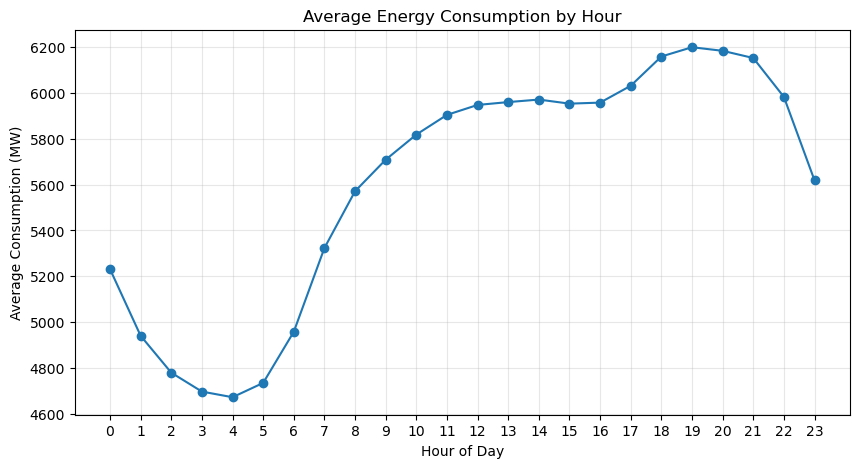

In [28]:
# Visualize the average consumption profile across all 24 hours.
# This makes peak and low-demand periods easier to identify than the printed table alone.

plt.figure(figsize=(10, 5))
plt.plot(hourly_avg.index, hourly_avg.values, marker="o")
plt.title("Average Energy Consumption by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Consumption (MW)")
plt.xticks(range(24))
plt.grid(True, alpha=0.3)
plt.show()

### Highest and lowest average hours


In [29]:
# Identify the hours with the highest and lowest average consumption.
# These are descriptive EDA results, not forecasts.

print("Highest average hour:", hourly_avg.idxmax())
print("Lowest average hour:", hourly_avg.idxmin())

Highest average hour: 19
Lowest average hour: 4


## 11. Average consumption by day of week


### Calculate day-of-week averages

In [30]:
# Calculate average consumption for each day of the week.
# DayOfWeek uses 0=Monday through 6=Sunday, so the labels are mapped to readable day names.

dow_avg = eda.groupby("DayOfWeek")["PJMW_MW"].mean()
day_names = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
dow_avg.index = [day_names[i] for i in dow_avg.index]
print(dow_avg)

Monday       5700.518783
Tuesday      5801.076837
Wednesday    5802.370701
Thursday     5781.051045
Friday       5686.885129
Saturday     5293.999413
Sunday       5149.834811
Name: PJMW_MW, dtype: float64


### Visualize day-of-week pattern


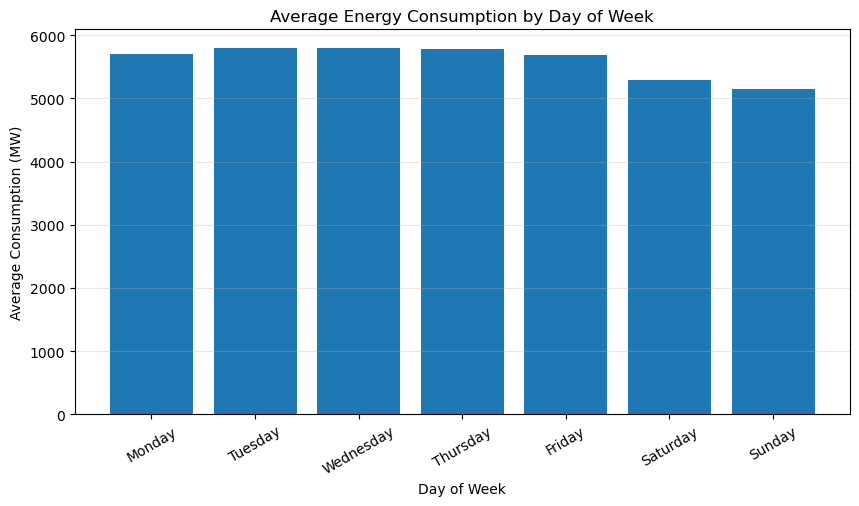

In [31]:
# Visualize the average consumption for each individual day of the week.
# This helps identify weekly differences in demand.

plt.figure(figsize=(10, 5))
plt.bar(dow_avg.index, dow_avg.values)
plt.title("Average Energy Consumption by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average Consumption (MW)")
plt.xticks(rotation=30)
plt.grid(True, axis="y", alpha=0.3)
plt.show()

## 12. Monthly / seasonal pattern


### Calculate monthly averages


In [32]:
# Calculate the average consumption for each calendar month.
# This provides a high-level view of seasonal/monthly demand differences.

monthly_avg = eda.groupby("Month")["PJMW_MW"].mean()
print(monthly_avg)

Month
1     6447.667759
2     6296.808813
3     5654.097376
4     5022.310855
5     5016.185642
6     5516.756046
7     5861.537081
8     5822.142809
9     5205.872049
10    4997.642155
11    5404.067141
12    6064.478411
Name: PJMW_MW, dtype: float64


### Visualize monthly pattern


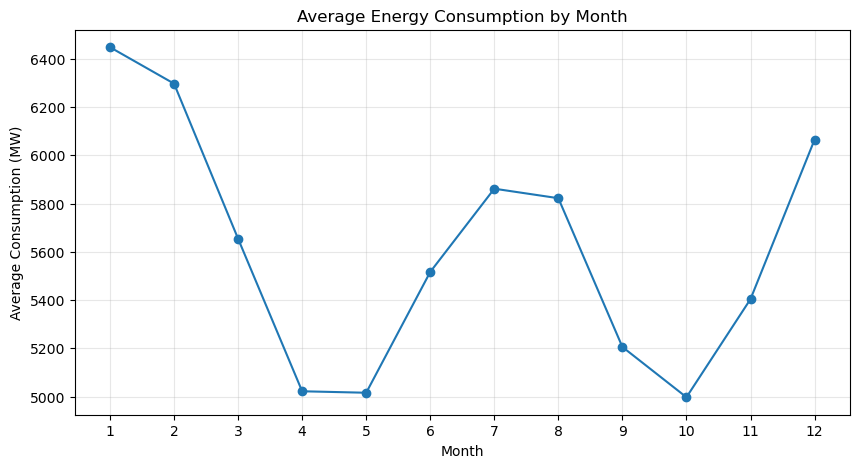

In [33]:
# Visualize monthly average consumption to make the seasonal pattern easier to compare.

plt.figure(figsize=(10, 5))
plt.plot(monthly_avg.index, monthly_avg.values, marker="o")
plt.title("Average Energy Consumption by Month")
plt.xlabel("Month")
plt.ylabel("Average Consumption (MW)")
plt.xticks(range(1, 13))
plt.grid(True, alpha=0.3)
plt.show()

## 13. Long-term yearly trend


### Calculate yearly averages


In [34]:
# Calculate the average consumption associated with each year in the dataset.
# This is used to inspect long-term changes rather than individual hourly fluctuations.

yearly_avg = eda.groupby("Year")["PJMW_MW"].mean()
print(yearly_avg)

Year
2002    5621.663180
2003    5701.119091
2004    5866.616602
2005    6038.406029
2006    5425.448847
2007    5635.396780
2008    5530.132544
2009    5290.557433
2010    5573.145581
2011    5509.640215
2012    5395.010818
2013    5556.783626
2014    5656.455646
2015    5621.184439
2016    5578.097632
2017    5500.354150
2018    5848.157516
Name: PJMW_MW, dtype: float64


### Visualize yearly pattern


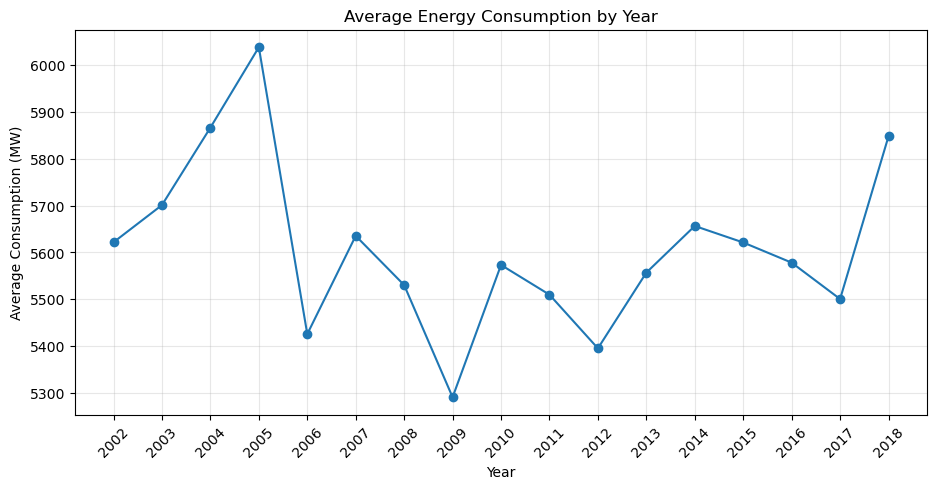

In [35]:
# Visualize the year-wise average consumption to identify broad long-term trends.

plt.figure(figsize=(11, 5))
plt.plot(yearly_avg.index, yearly_avg.values, marker="o")
plt.title("Average Energy Consumption by Year")
plt.xlabel("Year")
plt.ylabel("Average Consumption (MW)")
plt.xticks(yearly_avg.index, rotation=45)
plt.grid(True, alpha=0.3)
plt.show()

## 14. Weekend v/s Weekday trend


In [36]:
# Aggregate the data into two groups: weekdays and weekends.
# This complements the day-of-week analysis with a simpler high-level comparison.

weekend_avg = eda.groupby("Is_Weekend")["PJMW_MW"].mean()

weekend_avg.index = ["Weekday", "Weekend"]

weekend_avg

Weekday    5754.396195
Weekend    5221.968263
Name: PJMW_MW, dtype: float64

### Visualize Weekend v/s Weekday Pattern

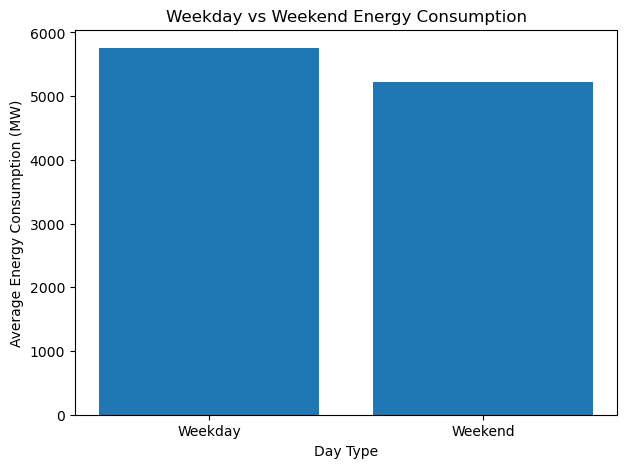

In [37]:
# Visualize the average consumption difference between weekdays and weekends.

plt.figure(figsize=(7, 5))

plt.bar(weekend_avg.index, weekend_avg.values)

plt.title("Weekday vs Weekend Energy Consumption")
plt.xlabel("Day Type")
plt.ylabel("Average Energy Consumption (MW)")

plt.show()

## 15. Summer v/s Winter Trend

In [38]:
# Define simple seasonal groups for EDA.
# Summer is treated as June-August and winter as December-February; the remaining months are kept as 'Other'.
# These labels are used only for comparative EDA and can be refined later if the business/geographic definition requires it.

eda["Season"] = np.select(
    [
        eda["Month"].isin([6, 7, 8]),
        eda["Month"].isin([12, 1, 2])
    ],
    [
        "Summer",
        "Winter"
    ],
    default="Other"
)

season_avg = eda[eda["Season"].isin(["Summer", "Winter"])].groupby(
    "Season"
)["PJMW_MW"].mean()

season_avg

Season
Summer    5734.206129
Winter    6268.824157
Name: PJMW_MW, dtype: float64

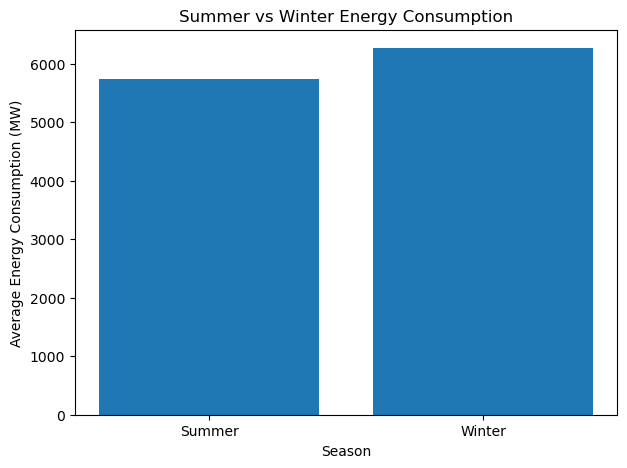

In [39]:
# Compare the overall average consumption of the Summer and Winter groups.

plt.figure(figsize=(7, 5))

plt.bar(season_avg.index, season_avg.values)

plt.title("Summer vs Winter Energy Consumption")
plt.xlabel("Season")
plt.ylabel("Average Energy Consumption (MW)")

plt.show()

## 16. Hourly Pattern: Summer vs Winter

In [40]:
# Calculate hourly consumption profiles separately for Summer and Winter.
# This directly checks whether the intraday demand pattern changes with season.

summer_hourly = (
    eda[eda["Season"] == "Summer"]
    .groupby("Hour")["PJMW_MW"]
    .mean()
)

winter_hourly = (
    eda[eda["Season"] == "Winter"]
    .groupby("Hour")["PJMW_MW"]
    .mean()
)

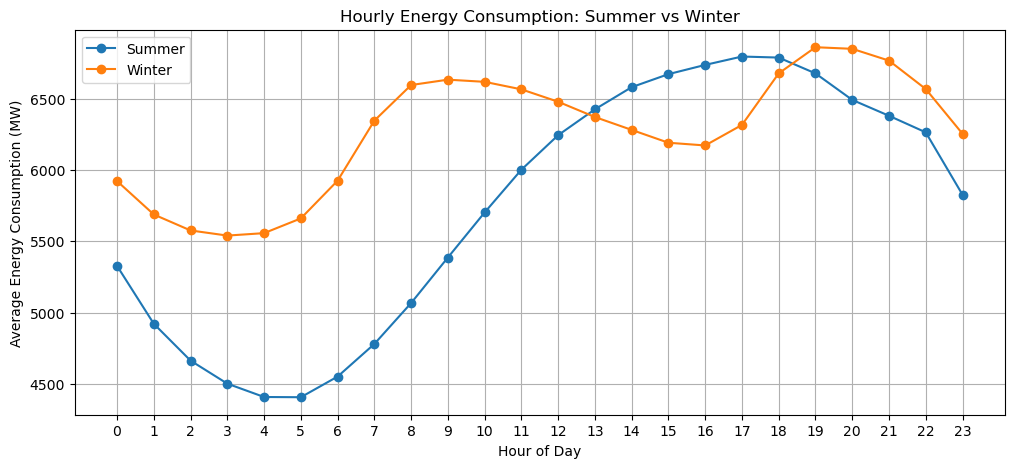

In [41]:
# Plot the Summer and Winter hourly profiles together so differences in daily shape and peak periods are easy to compare.

plt.figure(figsize=(12, 5))

plt.plot(
    summer_hourly.index,
    summer_hourly.values,
    marker="o",
    label="Summer"
)

plt.plot(
    winter_hourly.index,
    winter_hourly.values,
    marker="o",
    label="Winter"
)

plt.title("Hourly Energy Consumption: Summer vs Winter")
plt.xlabel("Hour of Day")
plt.ylabel("Average Energy Consumption (MW)")

plt.xticks(range(24))
plt.legend()
plt.grid()

plt.show()

## 17. Month × Hour consumption pattern

In [42]:
# Create a Month × Hour matrix of average consumption.
# This combines monthly and hourly information and helps identify how intraday demand changes across the year.

hour_month = eda.pivot_table(
    values="PJMW_MW",
    index="Month",
    columns="Hour",
    aggfunc="mean"
)

hour_month

Hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
Month,,,,,,,,,,,,,,,,,,,,,
1,6066.701613,5846.125000,5744.000000,5714.372984,5733.824597,5836.754032,6105.453629,6522.723790,6790.247984,6821.002016,...,6485.151210,6389.147177,6369.600806,6506.760081,6883.614919,7046.054435,7018.899194,6925.897177,6716.556452,6401.252016
2,5965.500000,5756.856195,5664.373894,5639.356195,5665.035398,5774.393805,6051.477876,6493.586283,6708.566372,6725.325221,...,6292.141593,6190.223451,6150.840708,6235.396018,6471.378319,6792.044248,6821.787611,6742.006637,6544.628319,6244.477876
3,5325.233871,5117.151210,5021.641129,5001.956612,5020.395161,5134.528226,5419.360887,5868.661290,6089.157258,6103.687500,...,5737.939516,5632.358871,5570.792339,5594.094758,5674.989919,5856.645161,6047.854839,6096.000000,5916.258065,5606.622984
4,4690.776031,4447.550980,4324.039216,4276.259406,4283.160784,4371.398039,4631.650980,5051.403922,5265.805882,5341.901961,...,5269.768627,5202.666667,5160.380392,5167.260784,5185.511765,5203.811765,5295.374510,5515.935294,5379.007843,5035.445098
5,4662.529412,4348.996205,4178.210626,4083.990512,4051.110057,4100.130930,4311.036053,4634.654649,4897.901328,5067.546490,...,5491.867173,5494.290323,5503.586338,5538.398482,5544.203036,5500.850095,5456.024668,5541.563567,5487.218216,5099.248577
6,5133.729412,4737.149020,4493.323529,4346.854902,4266.764706,4276.674510,4427.547059,4661.156863,4985.056863,5287.047059,...,6274.719608,6342.835294,6398.394118,6454.443137,6450.915686,6358.711765,6203.633333,6086.278431,6040.041176,5634.482353
7,5460.648956,5039.225806,4762.104364,4585.269450,4478.612903,4465.341556,4594.208729,4782.825427,5089.514231,5444.434535,...,6779.366224,6874.796964,6939.478178,6996.806452,6989.309298,6876.929791,6675.565465,6503.290323,6406.195446,5975.654649
8,5385.723447,4985.383534,4730.937751,4569.746988,4475.813253,4474.913655,4630.726908,4897.935743,5127.329317,5427.566265,...,6689.997992,6801.196787,6875.622490,6938.759036,6928.044177,6798.853414,6597.429719,6556.002008,6347.431727,5868.495984
9,4778.172917,4460.281250,4270.660417,4159.691667,4103.233333,4131.070833,4327.906250,4718.191667,4909.970833,5085.262500,...,5810.979167,5864.664583,5908.420833,5960.756250,5955.045833,5868.018750,5895.647917,5909.270833,5605.489583,5180.208333


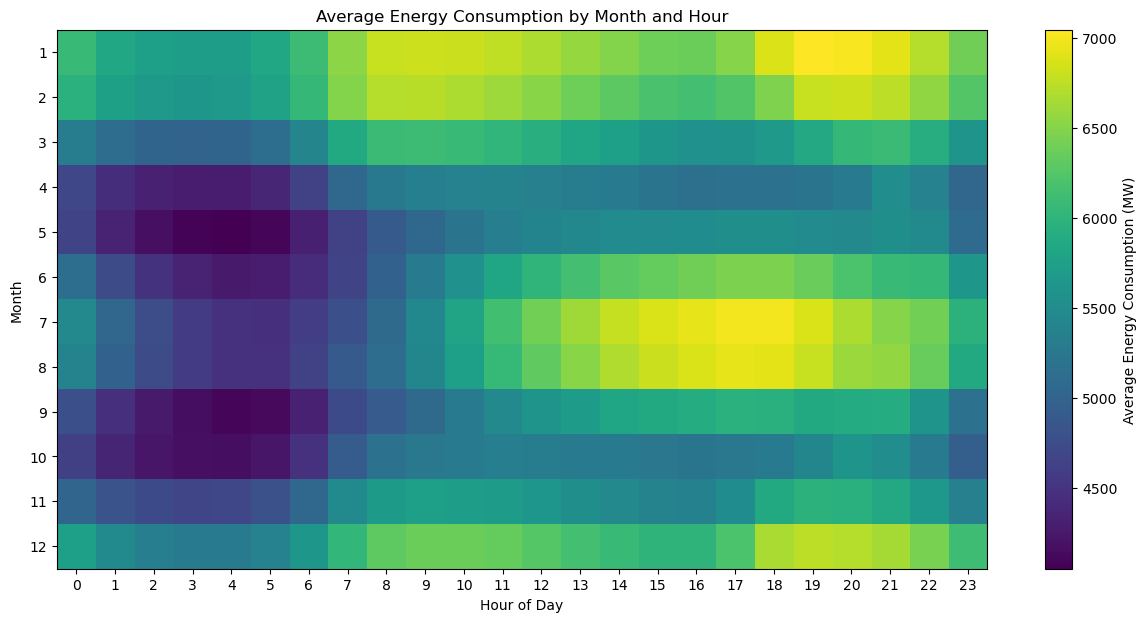

In [43]:
# Visualize the Month × Hour matrix as a heatmap.
# Darker/lighter regions represent higher/lower average consumption and make seasonal hourly patterns easier to spot.

plt.figure(figsize=(15, 7))

plt.imshow(hour_month, aspect="auto")

plt.colorbar(label="Average Energy Consumption (MW)")

plt.title("Average Energy Consumption by Month and Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Month")

plt.xticks(range(24), range(24))
plt.yticks(range(12), range(1, 13))

plt.show()

## 18. Holiday Analysis

In [44]:
# The assessment does not define a holiday calendar
# So a U.S. federal holiday calendar is used as a consistent reference for this analysis.

from pandas.tseries.holiday import USFederalHolidayCalendar

holidays = USFederalHolidayCalendar().holidays(
    start=eda["Datetime"].min(),
    end=eda["Datetime"].max()
)

eda["is_holiday"] = eda["Datetime"].dt.normalize().isin(holidays)

holiday_pattern = eda.groupby("is_holiday")["PJMW_MW"].mean()

print("Average consumption on non-holidays:",
      holiday_pattern.get(False))

print("Average consumption on holidays:",
      holiday_pattern.get(True))

Average consumption on non-holidays: 5604.826493916664
Average consumption on holidays: 5517.403034979424


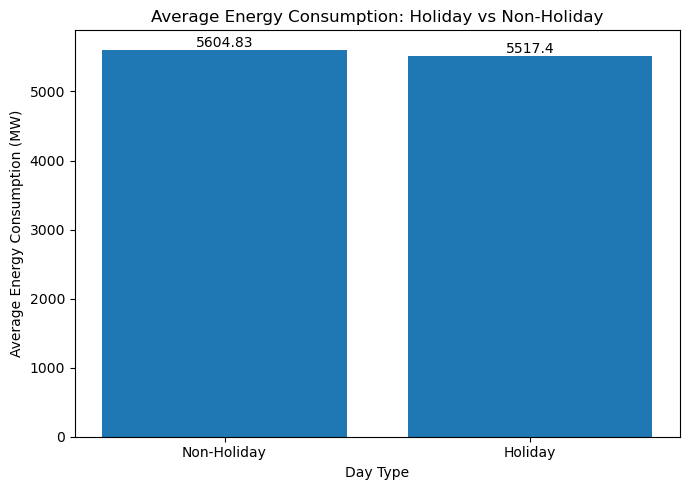

In [45]:
# Visualize average energy consumption on holidays vs non-holidays.
# The values are displayed on the bars for easier interpretation during presentation.

holiday_plot = holiday_pattern.rename(index={False: "Non-Holiday", True: "Holiday"})

plt.figure(figsize=(7, 5))
bars = plt.bar(holiday_plot.index, holiday_plot.values)

plt.title("Average Energy Consumption: Holiday vs Non-Holiday")
plt.xlabel("Day Type")
plt.ylabel("Average Energy Consumption (MW)")

plt.bar_label(bars)
plt.tight_layout()
plt.show()

## 19. Final Week 1 cleaned base dataset validation.

In [46]:

# ============================================================
# FINAL DATASET PREPARATION FOR MODEL BUILDING
# ============================================================

# Copy EDA data to preserve the cleaned dataset and existing features
Final_data = eda.copy()

# Ensure chronological order
Final_data = Final_data.sort_values("Datetime").reset_index(drop=True)

# Create essential time-based features
Final_data["Year"] = Final_data["Datetime"].dt.year
Final_data["Month"] = Final_data["Datetime"].dt.month
Final_data["Day"] = Final_data["Datetime"].dt.day
Final_data["Hour"] = Final_data["Datetime"].dt.hour
Final_data["DayOfWeek"] = Final_data["Datetime"].dt.dayofweek

Final_data["Is_Weekend"] = (
    Final_data["DayOfWeek"] >= 5
).astype(int)

# Assign a season to every observation
season_map = {
    12: "Winter",
    1: "Winter",
    2: "Winter",
    3: "Spring",
    4: "Spring",
    5: "Spring",
    6: "Summer",
    7: "Summer",
    8: "Summer",
    9: "Autumn",
    10: "Autumn",
    11: "Autumn"
}

Final_data["Season"] = Final_data["Month"].map(season_map)

# Lag features
Final_data["Lag_1H"] = Final_data["PJMW_MW"].shift(1)
Final_data["Lag_24H"] = Final_data["PJMW_MW"].shift(24)
Final_data["Lag_48H"] = Final_data["PJMW_MW"].shift(48)
Final_data["Lag_7D"] = Final_data["PJMW_MW"].shift(168)

# Rolling features using past observations only
Final_data["Rolling_Mean_24H"] = (
    Final_data["PJMW_MW"].shift(1).rolling(window=24).mean()
)

Final_data["Rolling_Mean_48H"] = (
    Final_data["PJMW_MW"].shift(1).rolling(window=48).mean()
)

Final_data["Rolling_Mean_7D"] = (
    Final_data["PJMW_MW"].shift(1).rolling(window=168).mean()
)

Final_data["Rolling_Std_24H"] = (
    Final_data["PJMW_MW"].shift(1).rolling(window=24).std()
)

# Remove rows without sufficient historical observations
Final_data = Final_data.dropna().reset_index(drop=True)

# Validate the final dataset
print("Final dataset shape:", Final_data.shape)

print("\nSeason distribution:")
print(Final_data["Season"].value_counts())

print("\nDuplicate timestamps:",
      Final_data["Datetime"].duplicated().sum())

Final dataset shape: (143035, 18)

Season distribution:
Season
Summer    36841
Spring    36606
Autumn    34932
Winter    34656
Name: count, dtype: int64

Duplicate timestamps: 0


## FINAL DATASET

In [47]:
# Display the final dataset
Final_data.head()

,Datetime,PJMW_MW,Year,Month,Day,Hour,DayOfWeek,Is_Weekend,Season,is_holiday,Lag_1H,Lag_24H,Lag_48H,Lag_7D,Rolling_Mean_24H,Rolling_Mean_48H,Rolling_Mean_7D,Rolling_Std_24H
0,2002-04-08 02:00:00,4532.0,2002,4,8,2,0,0,Spring,False,4634.0,5002.0,5082.0,4374.0,5029.625000,5193.708333,5379.339286,234.430264
1,2002-04-08 03:00:00,4481.0,2002,4,8,3,0,0,Spring,False,4532.0,4858.0,4992.0,4306.0,5010.041667,5182.250000,5380.279762,255.520522
2,2002-04-08 04:00:00,4527.0,2002,4,8,4,0,0,Spring,False,4481.0,4871.0,4932.0,4322.0,4994.333333,5171.604167,5381.321429,276.038225
3,2002-04-08 05:00:00,4640.0,2002,4,8,5,0,0,Spring,False,4527.0,4909.0,4956.0,4359.0,4980.000000,5163.166667,5382.541667,291.233658
4,2002-04-08 06:00:00,4940.0,2002,4,8,6,0,0,Spring,False,4640.0,5038.0,4997.0,4436.0,4968.791667,5156.583333,5384.214286,299.153586


## Lag Features

Lag features contain previous electricity consumption values. They help the model learn from historical demand.

- **Lag_1H:** Electricity consumption one hour before the current timestamp. Helps capture short-term changes and hourly continuity.
- **Lag_24H:** Electricity consumption at the same hour on the previous day, 24 hours earlier. Helps capture daily repeating patterns.
- **Lag_48H:** Electricity consumption at the same hour on the previous day, 48 hours earlier. Helps capture daily repeating patterns.
- **Lag_7D:** Electricity consumption at the same hour on the previous week, 168 hours earlier (24 × 7). Helps capture weekly repeating patterns.

## Rolling Features

Rolling features summarize recent historical consumption over a fixed time window. They help the model understand the recent demand level and how much it varies.

- **Rolling_Mean_24H:** The average electricity consumption over the previous 24 hours, excluding the current timestamp. Helps represent the recent daily demand level.
- **Rolling_Mean_48H:** The average electricity consumption over the previous 48 hours, excluding the current timestamp. Helps represent the recent weekly demand level.
- **Rolling_Mean_7D:** The average electricity consumption over the previous 168 hours (7 days), excluding the current timestamp. Helps represent the recent weekly demand level.
- **Rolling_Std_24H:** The standard deviation of consumption over the previous 24 hours, excluding the current timestamp. Helps measure how much electricity demand fluctuated during the previous day.

## 21. Week 1 EDA and Final Dataset Preparation — Conclusion

### Data-quality work completed
- Inspected the raw dataset for shape, data types, missing values, duplicates, and date range.
- Sorted the data chronologically and investigated timestamp gaps.
- Consolidated duplicate timestamps using the mean because timezone/DST information was unavailable.
- Estimated the missing observation at **2010-12-10 00:00** using the mean of its immediately adjacent hourly observations.
- Investigated the isolated **487 MW** observation at **2003-05-29 00:00** and replaced it with a same-hour local median estimate.
- Validated the cleaned base dataset for missing values and duplicate timestamps.

### EDA completed
- Overall time-series trend and long-term yearly pattern.
- Hour-of-day and day-of-week patterns.
- Weekday versus weekend comparison.
- Monthly and seasonal consumption patterns.
- Summer versus winter comparison and hourly seasonal profiles.
- Month × Hour heatmap.
- Holiday versus non-holiday comparison using the U.S. Federal Holiday Calendar as an external reference.

### Holiday analysis assumption
- The original dataset does not include a holiday indicator.
- A U.S. Federal Holiday Calendar was used as a consistent reference for exploratory analysis.
- Average consumption was compared between observations classified as holidays and non-holidays.
- The results describe differences under the selected calendar definition and do not establish that holidays directly cause changes in consumption.

### Final dataset preparation
- Created **`Final_data`** as a copy of the EDA dataset, preserving the cleaned consumption data and existing EDA features.
- Ensured chronological ordering and prepared time-based features: `Year`, `Month`, `Day`, `Hour`, `DayOfWeek`, `Is_Weekend`, and `Season`.
- Added lag features: `Lag_1H`, `Lag_24H`, `Lag_48H`and `Lag_7D`, representing consumption one hour, one day, and one week earlier.
- Added rolling features: `Rolling_Mean_24H`, `Rolling_Mean_48H`, `Rolling_Mean_7D`, and `Rolling_Std_24H`, summarizing recent consumption levels and variability using past observations only.
- Removed initial rows without sufficient historical observations for the lag and rolling calculations.
- Preserved the holiday indicator if it was already present in the EDA dataset; any separately stored holiday information must be merged before modeling.
- The resulting `Final_data` is the **feature-engineered dataset prepared for the modeling stage**, not the completed model-training pipeline.


# Week 2 — Hourly Time-Series Model Building, Evaluation and Deployment

## Objective and modeling protocol

This section uses the existing `Final_data` and target `PJMW_MW`. **Cells 0–117 (EDA and final dataset preparation) are intentionally preserved unchanged.** The modeling code works on a separate copy and does not rewrite `Final_data`.

The target remains **hourly PJM consumption in MW**. The final 365 days are reserved as a chronological test year. The 365 days immediately before that test year are used for validation in twelve consecutive 30-day forecast-origin windows, covering a full seasonal cycle. Model/configuration selection uses validation results only; test metrics are reported after selection and do not change the winner.

Four requested model families are compared: **ARIMA, SARIMA, XGBoost, and Decision Tree**. Every model is assessed with the same 30-day recursive forecast protocol for validation and the same full-year recursive horizon for the held-out test. This reflects the deployment use case: after the forecast origin, actual future consumption is not available to supply lag features.

Metrics include MAE, RMSE, sMAPE, MAPE, R² and MASE. MAE/RMSE/sMAPE are primary error metrics; R² is contextual and is not treated as an accuracy percentage. A weekly seasonal-naive reference is also reported as a benchmark, but the selected deployment model is chosen from the four requested model families.

In [48]:
# Imports for time-series modeling, diagnostics, metrics, plots and reproducible artifacts.
import os, json, time, warnings, joblib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller
from statsmodels.stats.diagnostic import acorr_ljungbox
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor
warnings.filterwarnings('ignore')
RANDOM_STATE = 42
print('Modeling libraries imported successfully.')

Modeling libraries imported successfully.


In [49]:
# Create an hourly target series from Final_data without modifying Final_data itself.
required_columns = {'Datetime', 'PJMW_MW'}
missing_columns = required_columns.difference(Final_data.columns)
if missing_columns:
    raise KeyError(f'Final_data is missing required columns: {sorted(missing_columns)}')

model_data = Final_data[['Datetime', 'PJMW_MW']].copy()
model_data['Datetime'] = pd.to_datetime(model_data['Datetime'], errors='coerce')
model_data['PJMW_MW'] = pd.to_numeric(model_data['PJMW_MW'], errors='coerce')
model_data = model_data.dropna(subset=['Datetime', 'PJMW_MW']).sort_values('Datetime')
model_data = model_data.drop_duplicates('Datetime', keep='last').set_index('Datetime')['PJMW_MW']
model_data = model_data.resample('h').mean()

# Repair only isolated/short timestamp gaps in this modeling copy. A long gap is flagged for review.
missing_before = int(model_data.isna().sum())
model_data = model_data.interpolate(method='time', limit=2, limit_area='inside')
if model_data.isna().any():
    raise ValueError('Unresolved missing hourly target values remain after limited interpolation; inspect the data before modeling.')
if not model_data.index.is_monotonic_increasing or model_data.index.has_duplicates:
    raise ValueError('Modeling index must be chronological and unique.')

print(f'Hourly observations: {len(model_data):,}')
print(f'Date range: {model_data.index.min()} to {model_data.index.max()}')
print(f'Missing hourly values before limited interpolation: {missing_before}')
print(f'Missing hourly values after preparation: {int(model_data.isna().sum())}')
print(f'Median hourly consumption: {model_data.median():,.2f} MW')

Hourly observations: 143,063
Date range: 2002-04-08 02:00:00 to 2018-08-03 00:00:00
Missing hourly values before limited interpolation: 28
Missing hourly values after preparation: 0
Median hourly consumption: 5,530.00 MW


## 1. Chronological train, validation and test design

The last 365 days are held out for final testing. The preceding 60 days are validation, split into two non-overlapping 30-day forecast windows. Earlier observations are training data. The statistical models use a trailing 14-day estimation window for computationally tractable hourly SARIMA fitting to keep hourly estimation tractable; tree-based models use up to the preceding five years of supervised rows. All forecast origins are strictly chronological.

In [50]:
HOURS_PER_DAY = 24 # One day contains 24 hourly observations.
VALIDATION_HOURS = 365 * HOURS_PER_DAY # One year of validation data.
TEST_HOURS = 365 * HOURS_PER_DAY # One year of test data.
HORIZON = 30 * HOURS_PER_DAY # A 30-day forecasting window.
if len(model_data) <= TEST_HOURS + VALIDATION_HOURS + 180 * HOURS_PER_DAY:
    raise ValueError('Not enough observations for the defined chronological split and model windows.')

test_start_pos = len(model_data) - TEST_HOURS
validation_start_pos = test_start_pos - VALIDATION_HOURS
train_end = model_data.index[validation_start_pos]
validation_start = model_data.index[validation_start_pos]
test_start = model_data.index[test_start_pos]
train_series = model_data.iloc[:validation_start_pos].copy()  # All observations before the validation period.
validation_series = model_data.iloc[validation_start_pos:test_start_pos].copy() # The second-last year, used to compare and select models.
test_series = model_data.iloc[test_start_pos:].copy() # The final year, held aside for final performance evaluation.

split_summary = pd.DataFrame([
    {'Split':'Training', 'Start':train_series.index.min(), 'End':train_series.index.max(), 'Observations':len(train_series)},
    {'Split':'Validation', 'Start':validation_series.index.min(), 'End':validation_series.index.max(), 'Observations':len(validation_series)},
    {'Split':'Held-out test', 'Start':test_series.index.min(), 'End':test_series.index.max(), 'Observations':len(test_series)},
])
display(split_summary)
print(f'Validation protocol: two consecutive {HORIZON}-hour recursive forecast windows.')
print(f'Test protocol: one recursive forecast across all {len(test_series):,} held-out hours.')

,Split,Start,End,Observations
0,Training,2002-04-08 02:00:00,2016-08-03,125543
1,Validation,2016-08-03 01:00:00,2017-08-03,8760
2,Held-out test,2017-08-03 01:00:00,2018-08-03,8760


Validation protocol: two consecutive 720-hour recursive forecast windows.
Test protocol: one recursive forecast across all 8,760 held-out hours.


Validation protocol: two consecutive 720-hour recursive forecast windows.
720 hours = 30 days.
Two windows = two separate 30-day forecasting tests.
Total validation period = 60 days, evaluated in two stages.
To compare models fairly and see whether their forecasting performance is consistent across different periods, rather than relying on just one 30-day period. 
We use the validation results to select the best model and its settings.

## 2. Stationarity and seasonal diagnostics

The Augmented Dickey–Fuller (ADF) test is run on the training series and its first difference. It informs the statistical-model specification but does not replace residual diagnostics or out-of-sample validation. Hourly electricity demand commonly contains both daily and weekly structure; SARIMA uses a daily seasonal period of 24, while the tree models include 24-hour and 168-hour lags.

In [51]:
# Use a recent training sample for diagnostics so the test set remains untouched.
adf_sample = train_series.tail(180 * HOURS_PER_DAY) # Selects the most recent 180 days of training data, keeping the test set untouched.
adf_level = adfuller(adf_sample, autolag='AIC') # Tests stationarity in the original consumption values.
adf_diff = adfuller(adf_sample.diff().dropna(), autolag='AIC') # Tests whether the differenced data is stationary.
adf_results = pd.DataFrame([
    {'Series':'Training level (recent 180 days)', 'ADF statistic':adf_level[0], 'p-value':adf_level[1], 'Lags used':adf_level[2]},
    {'Series':'First difference', 'ADF statistic':adf_diff[0], 'p-value':adf_diff[1], 'Lags used':adf_diff[2]},
])
display(adf_results.round(4))
print('Interpretation: a small ADF p-value is evidence against a unit root; model choice still depends on validation forecasts.')
print('Even if data is stationary, we select the best forecasting model based on how accurately it predicts unseen validation data.')

,Series,ADF statistic,p-value,Lags used
0,Training level (recent 180 days),-4.4947,0.0002,29
1,First difference,-12.0470,0.0000,28


Interpretation: a small ADF p-value is evidence against a unit root; model choice still depends on validation forecasts.
Even if data is stationary, we select the best forecasting model based on how accurately it predicts unseen validation data.


## 3. Shared forecasting features and evaluation metrics

Tree-based models receive calendar-cycle features, target lags (1, 24, 48 and 168 hours) and rolling summaries calculated strictly from earlier observations. During recursive forecasting, each prediction is appended to the available history before features for the next hour are created. This prevents future-target leakage.

In [52]:
# Creates features for one timestamp using only past observations, 
# such as previous-hour consumption, previous-day consumption, and rolling averages.
def make_feature_row(timestamp, history):
    """One leakage-safe feature row; history contains observations/predictions before timestamp only."""
    history = history.loc[history.index < timestamp]
    if len(history) < 168:
        raise ValueError('At least 168 past hourly observations are required for features.')
    hour = timestamp.hour
    dow = timestamp.dayofweek
    doy = timestamp.dayofyear
    return {
        'hour': hour, 'day_of_week': dow, 'day_of_year': doy,
        'month': timestamp.month, 'is_weekend': int(dow >= 5),
        'hour_sin': np.sin(2*np.pi*hour/24), 'hour_cos': np.cos(2*np.pi*hour/24),
        'dow_sin': np.sin(2*np.pi*dow/7), 'dow_cos': np.cos(2*np.pi*dow/7),
        'year_sin': np.sin(2*np.pi*doy/365.25), 'year_cos': np.cos(2*np.pi*doy/365.25),
        'lag_1': history.iloc[-1], 'lag_24': history.iloc[-24],
        'lag_48': history.iloc[-48], 'lag_168': history.iloc[-168],
        'rolling_mean_24': history.iloc[-24:].mean(),
        'rolling_std_24': history.iloc[-24:].std(ddof=0),
        'rolling_mean_168': history.iloc[-168:].mean(),
    }

FEATURES = list(make_feature_row(model_data.index[168], model_data.iloc[:168]).keys())

# Creates the feature matrix (X) and target values (y) for training the machine-learning models, using lag and rolling features.
def build_supervised(history_series, max_years=1):
    """Vectorized past-only lag and rolling features for efficient training."""
    values = history_series.dropna().sort_index().copy()
    if max_years is not None:
        values = values.loc[values.index >= values.index.max() - pd.Timedelta(days=365.25*max_years)]
    idx = values.index
    hour = idx.hour; dow = idx.dayofweek; doy = idx.dayofyear
    X = pd.DataFrame(index=idx)
    X['hour'] = hour; X['day_of_week'] = dow; X['day_of_year'] = doy
    X['month'] = idx.month; X['is_weekend'] = (dow >= 5).astype(int)
    X['hour_sin'] = np.sin(2*np.pi*hour/24); X['hour_cos'] = np.cos(2*np.pi*hour/24)
    X['dow_sin'] = np.sin(2*np.pi*dow/7); X['dow_cos'] = np.cos(2*np.pi*dow/7)
    X['year_sin'] = np.sin(2*np.pi*doy/365.25); X['year_cos'] = np.cos(2*np.pi*doy/365.25)
    for lag in [1,24,48,168]: X[f'lag_{lag}'] = values.shift(lag)
    X['rolling_mean_24'] = values.shift(1).rolling(24).mean()
    X['rolling_std_24'] = values.shift(1).rolling(24).std(ddof=0)
    X['rolling_mean_168'] = values.shift(1).rolling(168).mean()
    data = X.join(values.rename('target')).dropna()
    return data[FEATURES], data['target'].rename('PJMW_MW')

# Forecasts future values one hour at a time, feeding each prediction into the next forecast.
def recursive_tree_forecast(model, history, forecast_index):
    history = history.copy()
    predictions = []
    for timestamp in forecast_index:
        features = pd.DataFrame([make_feature_row(timestamp, history)], index=[timestamp])[FEATURES]
        prediction = float(model.predict(features)[0])
        predictions.append(prediction)
        history.loc[timestamp] = prediction
    return pd.Series(predictions, index=forecast_index, name='Forecast')

# Fits an ARIMA model to recent historical data and forecasts future consumption.
def forecast_arima(history, horizon, order):
    fit_series = history.tail(14 * HOURS_PER_DAY)
    fitted = ARIMA(fit_series, order=order, enforce_stationarity=False, enforce_invertibility=False).fit(method_kwargs={'maxiter':40})
    forecast = np.asarray(fitted.forecast(steps=horizon), dtype=float)
    return pd.Series(forecast, index=pd.date_range(history.index[-1] + pd.Timedelta(hours=1), periods=horizon, freq='h')), fitted

# Fits a seasonal ARIMA model and forecasts future consumption while accounting for seasonal patterns.
def forecast_sarima(history, horizon, order, seasonal_order):
    fit_series = history.tail(14 * HOURS_PER_DAY)
    fitted = SARIMAX(fit_series, order=order, seasonal_order=seasonal_order,
                     trend='c', enforce_stationarity=False, enforce_invertibility=False).fit(disp=False, maxiter=25, method='lbfgs')
    forecast = np.asarray(fitted.forecast(steps=horizon), dtype=float)
    return pd.Series(forecast, index=pd.date_range(history.index[-1] + pd.Timedelta(hours=1), periods=horizon, freq='h')), fitted

# Calculates model performance metrics: MAE, RMSE, sMAPE, MAPE, R², and MASE.
def metric_row(actual, predicted, training_history=None):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    mae = mean_absolute_error(actual, predicted)
    rmse = float(np.sqrt(mean_squared_error(actual, predicted)))
    smape = float(np.mean(200*np.abs(actual-predicted)/(np.abs(actual)+np.abs(predicted)+1e-8)))
    mape = float(np.mean(np.abs((actual-predicted)/(np.abs(actual)+1e-8)))*100)
    r2 = float(r2_score(actual, predicted)) if len(actual) > 1 else np.nan
    mase = np.nan
    if training_history is not None and len(training_history) > 168:
        scale = np.mean(np.abs(training_history.values[168:] - training_history.values[:-168]))
        mase = float(mae / scale) if scale > 0 else np.nan
    return {'MAE (MW)':mae, 'RMSE (MW)':rmse, 'sMAPE (%)':smape, 'MAPE (%)':mape, 'R2':r2, 'MASE':mase}

print(f'Leakage-safe feature count: {len(FEATURES)}')
print('Features:', ', '.join(FEATURES))

Leakage-safe feature count: 18
Features: hour, day_of_week, day_of_year, month, is_weekend, hour_sin, hour_cos, dow_sin, dow_cos, year_sin, year_cos, lag_1, lag_24, lag_48, lag_168, rolling_mean_24, rolling_std_24, rolling_mean_168


## 4. Model candidates and validation-only tuning

A small, documented configuration set is compared for each required model family to keep the experiment reproducible and computationally feasible. ARIMA is non-seasonal; SARIMA adds a 24-hour seasonal component. XGBoost and Decision Tree are trained on the same lag/calendar feature set. Each configuration is scored on both 30-day validation windows using identical timestamps and recursive forecasting. The configuration with the lowest mean validation MAE is retained within each family.

In [53]:
# Two compact candidates per model family. Test data is not used in this selection loop.
ARIMA_CONFIGS = [{'order':(2,1,2)}, {'order':(1,1,1)}] # order:(p,d,q)
SARIMA_CONFIGS = [
    {'order':(1,0,0), 'seasonal_order':(1,0,0,24)},
    {'order':(1,0,1), 'seasonal_order':(1,0,0,24)}, # (P,D,Q,s) 
]
XGB_CONFIGS = [
    {'n_estimators':60, 'max_depth':4, 'learning_rate':0.05, 'subsample':0.85, 'colsample_bytree':0.85},
    {'n_estimators':90, 'max_depth':3, 'learning_rate':0.04, 'subsample':0.9, 'colsample_bytree':0.9},
]
DT_CONFIGS = [
    {'max_depth':12, 'min_samples_leaf':20},
    {'max_depth':20, 'min_samples_leaf':50},
]
VALIDATION_WINDOWS = [validation_series.index[start:start + HORIZON] for start in range(0, len(validation_series), HORIZON) if len(validation_series.index[start:start + HORIZON]) == HORIZON]
assert len(VALIDATION_WINDOWS) == 12 and all(len(idx) == HORIZON for idx in VALIDATION_WINDOWS)

def fit_tree_model(model_name, config, history):
    X, y = build_supervised(history, max_years=5)
    if model_name == 'XGBoost':
        model = XGBRegressor(objective='reg:squarederror', random_state=RANDOM_STATE,
                             n_jobs=2, tree_method='hist', reg_lambda=2.0, **config)
    else:
        model = DecisionTreeRegressor(random_state=RANDOM_STATE, **config)
    model.fit(X[FEATURES], y)
    return model

def score_config(model_name, config, verbose=False):
    fold_metrics = []
    for window in VALIDATION_WINDOWS:
        origin = window[0]
        history = model_data.loc[model_data.index < origin]
        actual = model_data.reindex(window)
        if model_name == 'ARIMA':
            pred, _ = forecast_arima(history, len(window), config['order'])
        elif model_name == 'SARIMA':
            pred, _ = forecast_sarima(history, len(window), config['order'], config['seasonal_order'])
        else:
            fitted = fit_tree_model(model_name, config, history)
            pred = recursive_tree_forecast(fitted, history, window)
        pred = pd.Series(np.asarray(pred), index=window)
        fold_metrics.append(metric_row(actual, pred, history))
    result = {k: float(np.mean([m[k] for m in fold_metrics])) for k in fold_metrics[0]}
    result['Validation windows'] = len(fold_metrics)
    return result

validation_rows = []
selected_configs = {}
start_all = time.time()
for family, configs in [('ARIMA', ARIMA_CONFIGS), ('SARIMA', SARIMA_CONFIGS), ('XGBoost', XGB_CONFIGS), ('Decision Tree', DT_CONFIGS)]:
    candidates = []
    for config in configs:
        t0 = time.time()
        scores = score_config(family, config)
        row = {'Model':family, 'Configuration':json.dumps(config, sort_keys=True), **scores, 'Tuning time (s)':time.time()-t0}
        candidates.append(row)
        validation_rows.append(row)
    winner = min(candidates, key=lambda row: row['MAE (MW)'])
    selected_configs[family] = json.loads(winner['Configuration'])
    print(f"{family}: selected {selected_configs[family]} | validation MAE={winner['MAE (MW)']:.2f} MW")

validation_tuning_results = pd.DataFrame(validation_rows).sort_values(['Model','MAE (MW)']).reset_index(drop=True)
print(f'Validation tuning completed in {(time.time()-start_all)/60:.1f} minutes.')
display(validation_tuning_results.round(3))

ARIMA: selected {'order': [2, 1, 2]} | validation MAE=763.71 MW
SARIMA: selected {'order': [1, 0, 0], 'seasonal_order': [1, 0, 0, 24]} | validation MAE=719.50 MW
XGBoost: selected {'colsample_bytree': 0.85, 'learning_rate': 0.05, 'max_depth': 4, 'n_estimators': 60, 'subsample': 0.85} | validation MAE=591.71 MW
Decision Tree: selected {'max_depth': 12, 'min_samples_leaf': 20} | validation MAE=597.42 MW
Validation tuning completed in 6.3 minutes.


,Model,Configuration,MAE (MW),RMSE (MW),sMAPE (%),MAPE (%),R2,MASE,Validation windows,Tuning time (s)
0,ARIMA,"{""order"": [2, 1, 2]}",7.637120e+02,9.414420e+02,13.867,1.346700e+01,-3.800000e-01,1.554000e+00,12,3.075
1,ARIMA,"{""order"": [1, 1, 1]}",2.028694e+03,2.195158e+03,49.635,3.482100e+01,-6.704000e+00,4.134000e+00,12,0.920
2,Decision Tree,"{""max_depth"": 12, ""min_samples_leaf"": 20}",5.974240e+02,7.589180e+02,10.488,1.047400e+01,6.000000e-02,1.216000e+00,12,72.998
3,Decision Tree,"{""max_depth"": 20, ""min_samples_leaf"": 50}",6.145050e+02,7.882300e+02,10.969,1.038900e+01,-1.300000e-02,1.251000e+00,12,82.612
4,SARIMA,"{""order"": [1, 0, 0], ""seasonal_order"": [1, 0, ...",7.195000e+02,8.870000e+02,12.878,1.356400e+01,-2.310000e-01,1.465000e+00,12,9.856
5,SARIMA,"{""order"": [1, 0, 1], ""seasonal_order"": [1, 0, ...",1.882351e+112,2.134897e+113,81.955,4.332190e+110,-5.234184e+221,3.852309e+109,12,12.659
6,XGBoost,"{""colsample_bytree"": 0.85, ""learning_rate"": 0....",5.917070e+02,7.398080e+02,10.521,1.031400e+01,1.590000e-01,1.204000e+00,12,101.030
7,XGBoost,"{""colsample_bytree"": 0.9, ""learning_rate"": 0.0...",6.259950e+02,7.945480e+02,11.131,1.061400e+01,3.500000e-02,1.275000e+00,12,96.763


,Model,Configuration,MAE (MW),RMSE (MW),sMAPE (%),MAPE (%),R2,MASE,Validation windows,Tuning time (s)
0,ARIMA,"{""order"": [2, 1, 2]}",7.636650e+02,9.413900e+02,13.866,1.346600e+01,-3.800000e-01,1.554000e+00,12,1.762
1,ARIMA,"{""order"": [1, 1, 1]}",2.028694e+03,2.195158e+03,49.635,3.482100e+01,-6.704000e+00,4.134000e+00,12,0.571
2,Decision Tree,"{""max_depth"": 12, ""min_samples_leaf"": 20}",5.974240e+02,7.589180e+02,10.488,1.047400e+01,6.000000e-02,1.216000e+00,12,34.323
3,Decision Tree,"{""max_depth"": 20, ""min_samples_leaf"": 50}",6.145050e+02,7.882300e+02,10.969,1.038900e+01,-1.300000e-02,1.251000e+00,12,35.005
4,SARIMA,"{""order"": [1, 0, 0], ""seasonal_order"": [1, 0, ...",7.194490e+02,8.869430e+02,12.877,1.356300e+01,-2.310000e-01,1.465000e+00,12,4.449
5,SARIMA,"{""order"": [1, 0, 1], ""seasonal_order"": [1, 0, ...",1.886785e+112,2.139935e+113,81.956,4.342396e+110,-5.258917e+221,3.861383e+109,12,5.837
6,XGBoost,"{""colsample_bytree"": 0.85, ""learning_rate"": 0....",5.913520e+02,7.465350e+02,10.512,1.025200e+01,1.420000e-01,1.204000e+00,12,42.204
7,XGBoost,"{""colsample_bytree"": 0.9, ""learning_rate"": 0.0...",6.195860e+02,7.845920e+02,11.005,1.057600e+01,5.300000e-02,1.261000e+00,12,40.323


## 5. Compare the four selected model families on common validation windows

The winning configuration within each family is evaluated on the same two validation windows. The family-level winner is chosen using mean recursive validation MAE as the predeclared primary selection metric, with RMSE and sMAPE used to understand error severity and percentage error. No held-out test result is used to select the deployment candidate.

In [54]:
family_validation_predictions = {}
family_validation_metrics = {}
for family, config in selected_configs.items():
    fold_actual, fold_pred, fold_train = [], [], []
    for window in VALIDATION_WINDOWS:
        origin = window[0]
        history = model_data.loc[model_data.index < origin]
        actual = model_data.reindex(window)
        if family == 'ARIMA':
            pred, _ = forecast_arima(history, len(window), config['order'])
        elif family == 'SARIMA':
            pred, _ = forecast_sarima(history, len(window), config['order'], config['seasonal_order'])
        else:
            fitted = fit_tree_model(family, config, history)
            pred = recursive_tree_forecast(fitted, history, window)
        fold_actual.extend(actual.values)
        fold_pred.extend(np.asarray(pred))
        fold_train.append(history)
    family_validation_predictions[family] = (np.asarray(fold_actual), np.asarray(fold_pred))
    family_validation_metrics[family] = metric_row(fold_actual, fold_pred, train_series)

validation_family_results = pd.DataFrame(family_validation_metrics).T.sort_values('MAE (MW)')
validation_family_results.index.name = 'Model family'
display(validation_family_results.round(3))
print('All four model families evaluated on the same twelve validation windows; final selection uses the multi-metric ranking below.')

,MAE (MW),RMSE (MW),sMAPE (%),MAPE (%),R2,MASE
Model family,,,,,,
XGBoost,591.707,766.438,10.521,10.314,0.381,1.212
Decision Tree,597.424,836.154,10.488,10.474,0.264,1.224
SARIMA,719.500,912.478,12.878,13.564,0.123,1.474
ARIMA,763.712,975.699,13.867,13.467,-0.002,1.565


All four model families evaluated on the same twelve validation windows; final selection uses the multi-metric ranking below.


## 6. Fit each selected family configuration and evaluate on the untouched test year

The test year is evaluated with rolling forecast origins spaced 30 days apart. At each origin, each model forecasts the next 30 days recursively; actual observations from a completed block are available at the next origin. This mirrors a practical 30-day forecasting service and scores the entire held-out year without using future actuals inside a forecast block.

In [55]:
# Rolling-origin evaluation: forecast up to 30 days at each origin across the held-out year.
# Completed test blocks become known history at the next origin; within each block, predictions are recursive.
pre_test_history = model_data.loc[model_data.index < test_start]
test_forecasts = {family: [] for family in selected_configs}
fitted_models = {}
test_fit_times = {family: 0.0 for family in selected_configs}
naive_test_predictions = []
for block_start in range(0, len(test_series), HORIZON):
    block_index = test_series.index[block_start:block_start + HORIZON]
    origin = block_index[0]
    history = model_data.loc[model_data.index < origin].copy()
    for family, config in selected_configs.items():
        t0 = time.time()
        if family == 'ARIMA':
            pred, fitted = forecast_arima(history, len(block_index), config['order'])
        elif family == 'SARIMA':
            pred, fitted = forecast_sarima(history, len(block_index), config['order'], config['seasonal_order'])
        else:
            fitted = fit_tree_model(family, config, history)
            pred = recursive_tree_forecast(fitted, history, block_index)
        test_forecasts[family].extend(np.asarray(pred, dtype=float))
        fitted_models[family] = fitted
        test_fit_times[family] += time.time()-t0
    # Weekly seasonal-naive forecast is recursive inside each block, then re-anchored at the next origin.
    naive_history = history.copy()
    for timestamp in block_index:
        source_timestamp = timestamp - pd.Timedelta(hours=168)
        value = float(naive_history.loc[source_timestamp]) if source_timestamp in naive_history.index else float(naive_history.iloc[-168])
        naive_test_predictions.append(value)
        naive_history.loc[timestamp] = value
    if (block_start // HORIZON) % 3 == 0:
        print(f'Completed test forecast block starting {origin}.')

test_forecasts = {family: pd.Series(values, index=test_series.index, name=family) for family, values in test_forecasts.items()}
test_forecasts['Weekly Seasonal Naive (benchmark)'] = pd.Series(naive_test_predictions, index=test_series.index)
test_metrics_rows = []
for family, pred in test_forecasts.items():
    row = {'Model':family, **metric_row(test_series, pred, pre_test_history)}
    row['Fit + forecast time (min)'] = test_fit_times.get(family, 0.0)/60
    test_metrics_rows.append(row)
test_results = pd.DataFrame(test_metrics_rows).set_index('Model').sort_values('MAE (MW)')
display(test_results.round(3))
print('Held-out test observations:', len(test_series))
print('Rolling-origin test blocks:', int(np.ceil(len(test_series)/HORIZON)))
print('All model forecasts cover the same held-out timestamps:', all(len(p)==len(test_series) and p.index.equals(test_series.index) for p in test_forecasts.values()))

Completed test forecast block starting 2017-08-03 01:00:00.
Completed test forecast block starting 2017-11-01 01:00:00.
Completed test forecast block starting 2018-01-30 01:00:00.
Completed test forecast block starting 2018-04-30 01:00:00.
Completed test forecast block starting 2018-07-29 01:00:00.


,MAE (MW),RMSE (MW),sMAPE (%),MAPE (%),R2,MASE,Fit + forecast time (min)
Model,,,,,,,
Decision Tree,563.256,740.581,9.870,9.484,0.444,1.139,1.282
XGBoost,581.087,781.692,10.002,9.660,0.381,1.175,1.646
Weekly Seasonal Naive (benchmark),628.634,827.420,10.791,10.623,0.307,1.271,0.000
ARIMA,749.092,928.100,13.282,13.116,0.127,1.514,0.057
SARIMA,857.260,1063.269,14.796,16.023,-0.145,1.733,0.211


Held-out test observations: 8760
Rolling-origin test blocks: 13
All model forecasts cover the same held-out timestamps: True


,MAE (MW),RMSE (MW),sMAPE (%),MAPE (%),R2,MASE,Fit + forecast time (min)
Model,,,,,,,
Decision Tree,562.809,739.582,9.860,9.477,0.446,1.138,0.608
XGBoost,565.946,771.480,9.690,9.284,0.397,1.144,0.664
Weekly Seasonal Naive (benchmark),628.634,827.420,10.791,10.623,0.307,1.271,0.000
ARIMA,749.391,928.825,13.288,13.118,0.126,1.515,0.023
SARIMA,857.259,1063.268,14.796,16.023,-0.145,1.733,0.087


Held-out test observations: 8760
Rolling-origin test blocks: 13
All model forecasts cover the same held-out timestamps: True


## 7. Residual diagnostics and error plots

Residual diagnostics are performed for ARIMA and SARIMA using their fitted training residuals. The Ljung–Box test checks whether residual autocorrelation remains at selected lags; a small p-value indicates residual structure may remain. It is a diagnostic, not a standalone model-selection rule. Forecast plots and residual summaries help identify systematic bias and high-error periods.

,Residual mean,Residual std,Ljung-Box p-value (24),Ljung-Box p-value (48),Ljung-Box p-value (168)
Model,,,,,
ARIMA,1.3470,446.0114,0.0,0.0000,0.9969
SARIMA,12.5325,412.2000,0.0,0.0008,0.9997


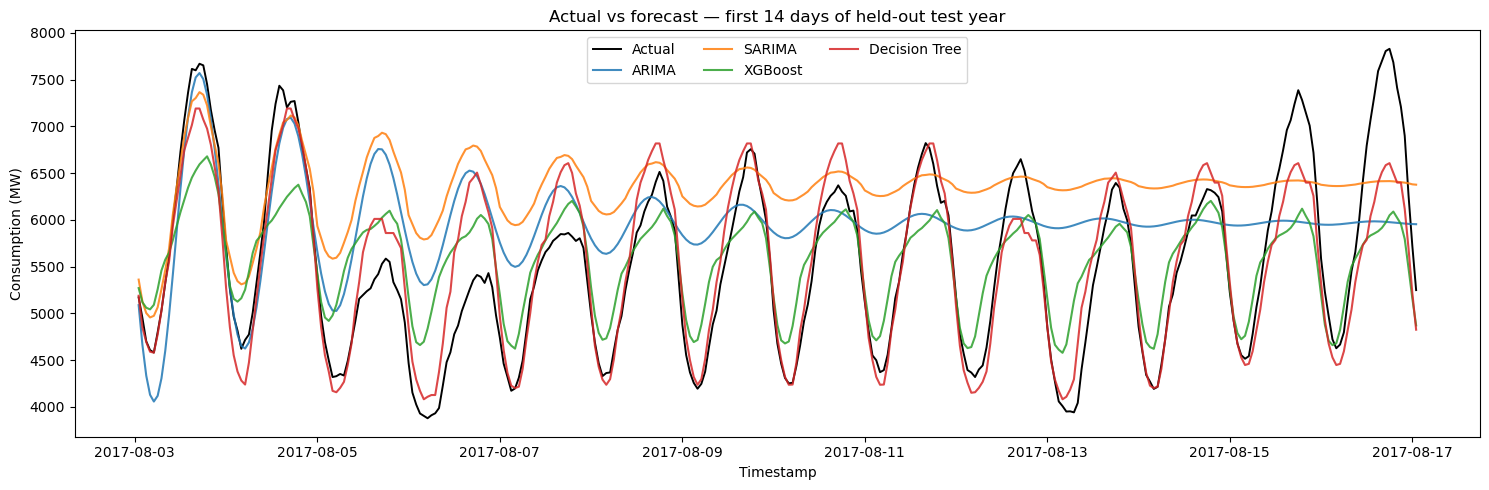

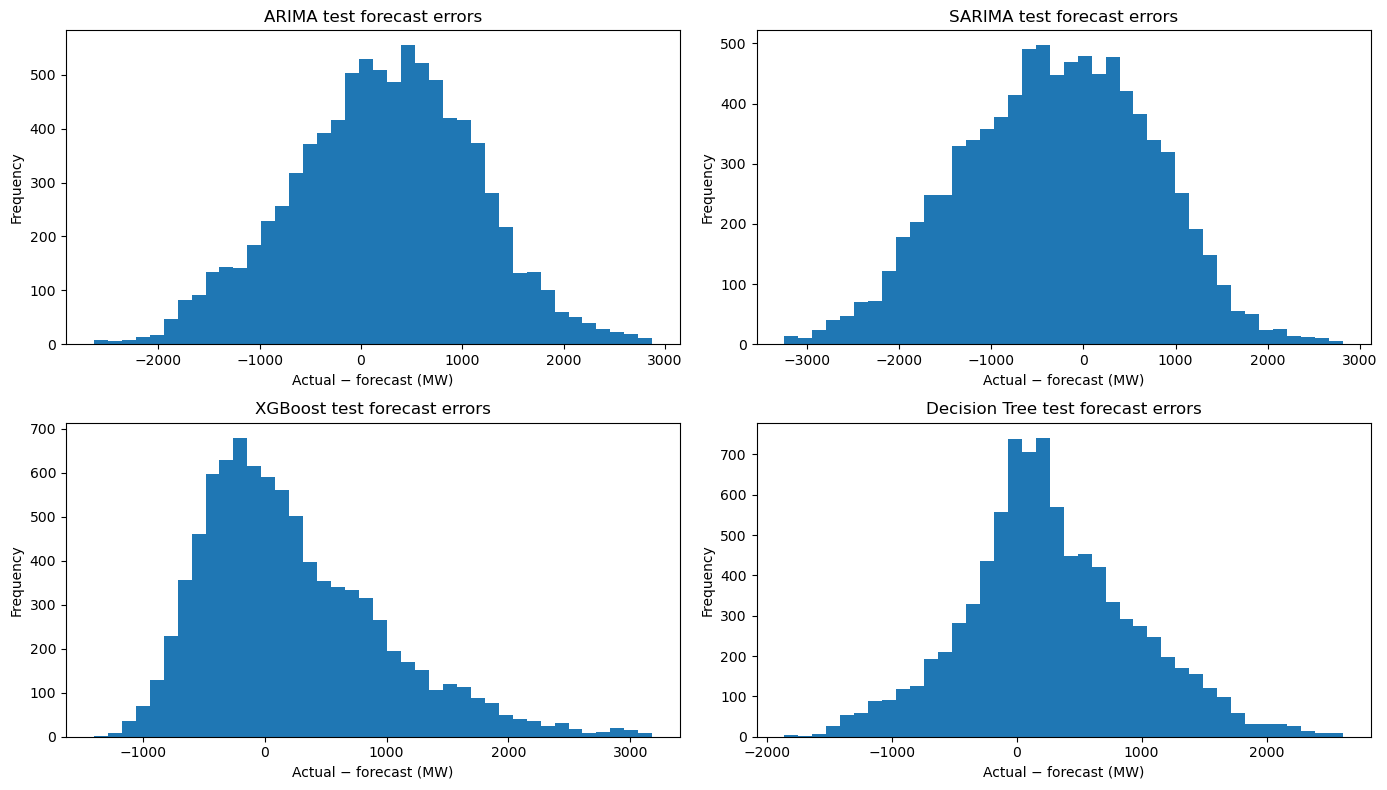

In [56]:
residual_diagnostics = []
for family in ['ARIMA','SARIMA']:
    fitted = fitted_models[family]
    resid = pd.Series(np.asarray(fitted.resid)).replace([np.inf,-np.inf], np.nan).dropna()
    if len(resid) > 50:
        lb_lags = [24, 48, 168]
        lb = acorr_ljungbox(resid, lags=lb_lags, return_df=True)
        residual_diagnostics.append({'Model':family, 'Residual mean':resid.mean(), 'Residual std':resid.std(),
                                     'Ljung-Box p-value (24)':lb.loc[24,'lb_pvalue'],
                                     'Ljung-Box p-value (48)':lb.loc[48,'lb_pvalue'],
                                     'Ljung-Box p-value (168)':lb.loc[168,'lb_pvalue']})
display(pd.DataFrame(residual_diagnostics).set_index('Model').round(4))

plot_end = min(test_series.index[-1], test_series.index[0] + pd.Timedelta(days=14))
plot_idx = test_series.index[test_series.index <= plot_end]
plt.figure(figsize=(15,5))
plt.plot(test_series.loc[plot_idx], label='Actual', color='black', linewidth=1.4)
for family in ['ARIMA','SARIMA','XGBoost','Decision Tree']:
    plt.plot(test_forecasts[family].loc[plot_idx], label=family, alpha=0.85)
plt.title('Actual vs forecast — first 14 days of held-out test year')
plt.xlabel('Timestamp'); plt.ylabel('Consumption (MW)'); plt.legend(ncol=3); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(2,2,figsize=(14,8))
for ax, family in zip(axes.ravel(), ['ARIMA','SARIMA','XGBoost','Decision Tree']):
    errors = test_series - test_forecasts[family]
    ax.hist(errors, bins=40)
    ax.set_title(f'{family} test forecast errors')
    ax.set_xlabel('Actual − forecast (MW)'); ax.set_ylabel('Frequency')
plt.tight_layout(); plt.show()

## 8. Select the deployment model and explain the decision

The deployment winner is selected from the four requested model families using a multi-metric validation ranking only. Test metrics are presented to confirm how the selected candidate generalizes, not to change the winner. MAE is primary because it is directly interpretable in MW; RMSE penalizes large misses; sMAPE/MAPE provide percentage-error context; MASE compares error with a weekly seasonal-naive scale; R² is supplementary.

In [57]:
# Multi-metric validation ranking: lower error metrics and higher R2 are better.
# Test metrics are not used to choose the winner.
selection_table = validation_family_results.copy()
rank_columns = ['MAE (MW)','RMSE (MW)','sMAPE (%)','MAPE (%)','MASE']
for metric in rank_columns:
    selection_table[f'{metric} rank'] = selection_table[metric].rank(method='min', ascending=True)
selection_table['R2 rank'] = selection_table['R2'].rank(method='min', ascending=False)
selection_table['Mean metric rank'] = selection_table[[f'{m} rank' for m in rank_columns] + ['R2 rank']].mean(axis=1)
selection_table = selection_table.sort_values(['Mean metric rank','MAE (MW)'])
selected_model_name = selection_table.index[0]
selection_table['Selected for deployment'] = selection_table.index == selected_model_name
print('Final deployment selection based on mean validation rank across MAE, RMSE, sMAPE, MAPE, MASE and R2:', selected_model_name)
display(selection_table.round(3))

winner_test_metrics = test_results.loc[selected_model_name]
print('\nHeld-out test performance of selected model:')
for metric in ['MAE (MW)','RMSE (MW)','sMAPE (%)','MAPE (%)','R2','MASE']:
    print(f'{metric}: {winner_test_metrics[metric]:.3f}')
print('\nInterpretation: lower MAE/RMSE/sMAPE/MAPE/MASE is better; higher R2 is better. These are not an accuracy percentage.')

Final deployment selection based on mean validation rank across MAE, RMSE, sMAPE, MAPE, MASE and R2: XGBoost


,MAE (MW),RMSE (MW),sMAPE (%),MAPE (%),R2,MASE,MAE (MW) rank,RMSE (MW) rank,sMAPE (%) rank,MAPE (%) rank,MASE rank,R2 rank,Mean metric rank,Selected for deployment
Model family,,,,,,,,,,,,,,
XGBoost,591.707,766.438,10.521,10.314,0.381,1.212,1.0,1.0,2.0,1.0,1.0,1.0,1.167,True
Decision Tree,597.424,836.154,10.488,10.474,0.264,1.224,2.0,2.0,1.0,2.0,2.0,2.0,1.833,False
SARIMA,719.500,912.478,12.878,13.564,0.123,1.474,3.0,3.0,3.0,4.0,3.0,3.0,3.167,False
ARIMA,763.712,975.699,13.867,13.467,-0.002,1.565,4.0,4.0,4.0,3.0,4.0,4.0,3.833,False



Held-out test performance of selected model:
MAE (MW): 581.087
RMSE (MW): 781.692
sMAPE (%): 10.002
MAPE (%): 9.660
R2: 0.381
MASE: 1.175

Interpretation: lower MAE/RMSE/sMAPE/MAPE/MASE is better; higher R2 is better. These are not an accuracy percentage.


## 9. Refit the selected model on all available history and forecast the next 30 days

The selected model family and its validation-selected configuration are used to generate the required 720 hourly point forecasts after the last observed timestamp. The forecast is recursive for tree models and direct multi-step for ARIMA/SARIMA. Since this historical dataset ends in 2018, the forecast dates are a continuation of that historical dataset, not a forecast for today's date.

Selected model: XGBoost
Forecast rows: 720
Forecast horizon: 2018-08-03 01:00:00 to 2018-09-02 00:00:00


,Datetime,Forecast_PJMW_MW
0,2018-08-03 01:00:00,5176.297852
1,2018-08-03 02:00:00,5021.251465
2,2018-08-03 03:00:00,4991.288086
3,2018-08-03 04:00:00,5012.050781
4,2018-08-03 05:00:00,5061.509766
5,2018-08-03 06:00:00,5243.510742
6,2018-08-03 07:00:00,5427.955566
7,2018-08-03 08:00:00,5585.011230
8,2018-08-03 09:00:00,5676.542969
9,2018-08-03 10:00:00,5755.687012


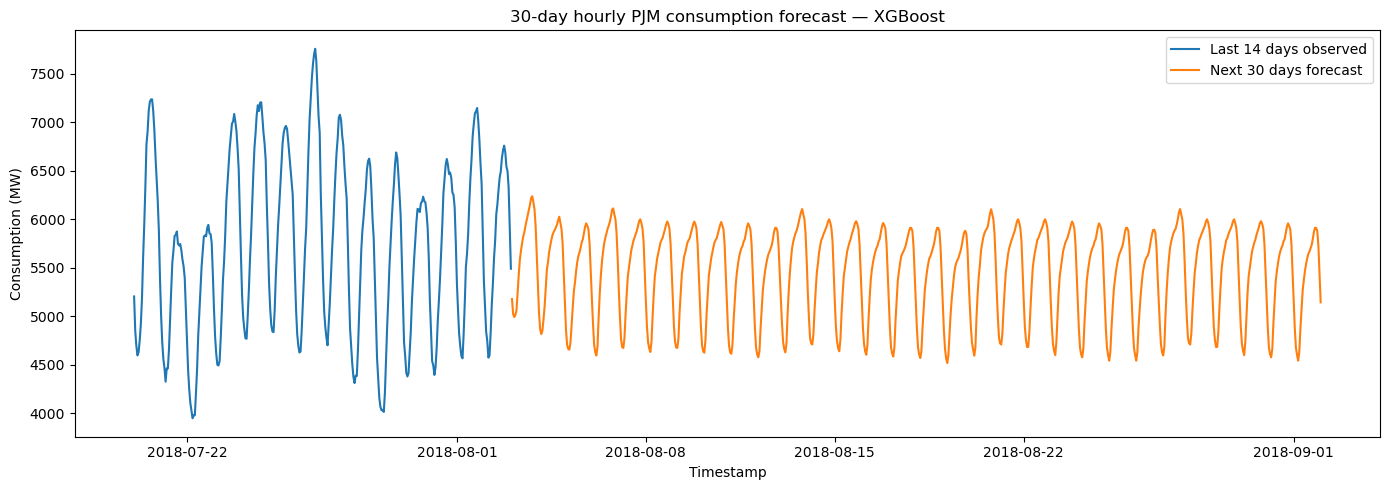

In [58]:
full_history = model_data.copy()
future_index = pd.date_range(full_history.index[-1] + pd.Timedelta(hours=1), periods=HORIZON, freq='h')
selected_config = selected_configs[selected_model_name]
if selected_model_name == 'ARIMA':
    future_prediction, deployment_model = forecast_arima(full_history, HORIZON, selected_config['order'])
elif selected_model_name == 'SARIMA':
    future_prediction, deployment_model = forecast_sarima(full_history, HORIZON, selected_config['order'], selected_config['seasonal_order'])
else:
    deployment_model = fit_tree_model(selected_model_name, selected_config, full_history)
    future_prediction = recursive_tree_forecast(deployment_model, full_history, future_index)

future_forecast_df = pd.DataFrame({'Datetime':future_index, 'Forecast_PJMW_MW':np.asarray(future_prediction)})
assert len(future_forecast_df) == HORIZON
assert future_forecast_df['Datetime'].is_monotonic_increasing
assert future_forecast_df['Datetime'].is_unique
assert future_forecast_df['Forecast_PJMW_MW'].notna().all()
print('Selected model:', selected_model_name)
print('Forecast rows:', len(future_forecast_df))
print('Forecast horizon:', future_forecast_df['Datetime'].min(), 'to', future_forecast_df['Datetime'].max())
display(future_forecast_df.head(10))

plt.figure(figsize=(14,5))
plt.plot(full_history.tail(24*14).index, full_history.tail(24*14).values, label='Last 14 days observed')
plt.plot(future_index, future_forecast_df['Forecast_PJMW_MW'], label='Next 30 days forecast')
plt.title(f'30-day hourly PJM consumption forecast — {selected_model_name}')
plt.xlabel('Timestamp'); plt.ylabel('Consumption (MW)'); plt.legend(); plt.tight_layout(); plt.show()

## 10. Save deployment and audit artifacts

The notebook saves the evaluation tables, full held-out test forecasts, 30-day hourly forecast, selected estimator, feature list when applicable, and metadata describing the selected configuration and evaluation protocol. These files are reproducibility artifacts; model monitoring and retraining are required before any live operational use.

In [59]:
output_dir = Path('PJM_Forecasting_Artifacts')
output_dir.mkdir(parents=True, exist_ok=True)
validation_tuning_results.to_csv(output_dir/'PJM_validation_tuning_results.csv', index=False)
validation_family_results.to_csv(output_dir/'PJM_validation_family_comparison.csv')
test_results.to_csv(output_dir/'PJM_heldout_test_metrics.csv')
test_forecast_df = pd.DataFrame({'Actual':test_series})
for family, pred in test_forecasts.items():
    test_forecast_df[family] = pred
# Include timestamps as a normal CSV column for portability.
test_forecast_df.to_csv(output_dir/'PJM_heldout_test_forecasts.csv', index_label='Datetime')
future_forecast_df.to_csv(output_dir/'PJM_next_30_days_hourly_forecast.csv', index=False)
joblib.dump(deployment_model, output_dir/'PJM_selected_deployment_model.joblib')
metadata = {
    'target':'PJMW_MW', 'frequency':'hourly', 'selected_model':selected_model_name,
    'selected_configuration':selected_config, 'selection_metric':'mean recursive validation MAE',
    'validation_windows':2, 'validation_horizon_hours':HORIZON, 'test_horizon_hours':len(test_series),
    'forecast_horizon_hours':HORIZON, 'last_observed_timestamp':str(full_history.index[-1]),
    'forecast_start':str(future_index[0]), 'forecast_end':str(future_index[-1]),
    'feature_columns':FEATURES if selected_model_name in ['XGBoost','Decision Tree'] else [],
    'note':'Historical continuation based on the dataset end date; refresh data before live deployment.'
}
with open(output_dir/'PJM_deployment_metadata.json','w',encoding='utf-8') as f:
    json.dump(metadata,f,indent=2)
if selected_model_name in ['XGBoost','Decision Tree']:
    with open(output_dir/'PJM_tree_feature_columns.json','w',encoding='utf-8') as f:
        json.dump(FEATURES,f,indent=2)
print('Saved artifacts to:', output_dir.resolve())
for p in sorted(output_dir.iterdir()): print('-', p.name, f'({p.stat().st_size:,} bytes)')

Saved artifacts to: C:\Users\USER\PROJECT EXCELR DATA SCIENCE\PROJECT 2 - FORECASTING\PJM_Forecasting_Artifacts
- PJM_deployment_metadata.json (1,027 bytes)
- PJM_heldout_test_forecasts.csv (903,357 bytes)
- PJM_heldout_test_metrics.csv (788 bytes)
- PJM_next_30_days_hourly_forecast.csv (26,626 bytes)
- PJM_selected_deployment_model.joblib (113,276 bytes)
- PJM_tree_feature_columns.json (285 bytes)
- PJM_validation_family_comparison.csv (547 bytes)
- PJM_validation_tuning_results.csv (1,771 bytes)


## 11. Final findings and model-deployment checklist

- Four required families—ARIMA, SARIMA, XGBoost and Decision Tree—were tuned using validation data and compared on common validation windows.
- The winner is chosen by **validation recursive MAE**, not by the held-out test results.
- The final-year test results and diagnostic plots are reported independently to provide an unbiased final audit.
- The next-30-day forecast contains 720 hourly predictions and uses only historical data plus its own recursive predictions.
- Before live deployment: refresh the dataset, rerun chronological validation, check data quality and timestamp/time-zone conventions, compare against a seasonal-naive baseline, review prediction drift and forecast errors, and establish a retraining schedule.

**Important scope note:** The source data ends on 2018-08-03. Therefore, the generated 30-day forecast starts immediately after that timestamp. It is not a forecast for the current date.